# Lote 1 — Rotulação de 50 questões CEDERJ + Parte B (Vetorização 2.000 Lemas)
**Ambiente exigido:** Google Colab — Runtime **GPU L4 (24 GB)** (`python3`).

In [1]:
# 1. Confirmar GPU (Esperado: NVIDIA L4 24 GB) e versões base
!nvidia-smi
import torch
print(f"PyTorch: {torch.__version__} | CUDA disponível: {torch.cuda.is_available()}")
assert torch.cuda.is_available(), "ERRO: O kernel está sem GPU (CPU)! No topo direito do VS Code, clique no seletor de Kernel -> Colab -> New Colab Server -> GPU -> L4."
gpu_name = torch.cuda.get_device_name(0)
vram_gb = round(torch.cuda.get_device_properties(0).total_memory / (1024**3), 2)
print(f"GPU detectada: {gpu_name} | VRAM: {vram_gb} GB")


Mon Nov  2 19:40:43 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   35C    P8             12W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [4]:
# 2. Montar Google Drive ANTES de rodar (Obrigatório para checkpoint)
# Dica VS Code Colab: se drive.mount pedir confirmação ou falhar na célula,
# clique no botão 'Colab' no topo do notebook -> 'Mount Google Drive to Server...'
import os, json
if not os.path.ismount('/content/drive'):
    from google.colab import drive
    drive.mount('/content/drive')

PIPELINE_DIR = '/content/drive/MyDrive/lemmas-pipeline'
assert os.path.isdir(PIPELINE_DIR), f"Pasta não encontrada: {PIPELINE_DIR} (verifique se o Drive está montado na conta guiguimendes2002@gmail.com)"

arquivos = sorted(os.listdir(PIPELINE_DIR))
print("Arquivos em lemmas-pipeline:", arquivos)

for req in ['questoes_lote1.json', 'passo4_rotulacao_lote1.py', 'lemas_catalogo.json']:
    p = os.path.join(PIPELINE_DIR, req)
    assert os.path.isfile(p), f"Arquivo obrigatório ausente no Drive: {req}"
    print(f"[OK] {req} ({os.path.getsize(p):,} bytes)")

with open(os.path.join(PIPELINE_DIR, 'questoes_lote1.json'), 'r', encoding='utf-8') as f:
    q_lote1 = json.load(f)
print(f"Total de questões em questoes_lote1.json: {len(q_lote1)}")


Arquivos em lemmas-pipeline: ['ancoragem_62_dispersao.png', 'ancoragem_62_heatmap_S_enun.png', 'ancoragem_62_heatmap_S_fam.png', 'ancoragem_62_heatmap_S_lema.png', 'ancoragem_62_relatorio.json', 'ancoragem_62_similaridade.png', 'ancoragem_vetorial_62.json', 'heatmap_hibrida_aux07.png', 'heatmap_hibrida_norm.png', 'heatmap_hibrida_pesos-iguais.png', 'heatmap_hibrida_v2.png', 'heatmap_hibrida_v3.png', 'heatmap_semantica_norm.png', 'heatmap_semantica_v2.png', 'heatmap_semantica_v3.png', 'lemas_3k.json', 'lemas_3k_ordem.json', 'lemas_catalogo.json', 'lemas_duplicatas_3k.json', 'lemas_isomorfismos_3k.json', 'lemas_primos_3k.json', 'lemas_similaridade_3k.npy', 'lemas_similaridade_form_3k.npy', 'lemas_similaridade_top10_3k.json', 'lemas_super_familias_3k.json', 'lemas_super_familias_metricas_ml.json', 'lemas_vetores_3k.json', 'lemas_vetores_3k_v2_parcial.jsonl', 'lote1_resolucoes_final.tex', 'metodos_amostra_v2.json', 'metodos_lote1.json', 'metodos_lote1_final.json', 'metodos_lote1_norm.json'

In [4]:
# 3. Instalação controlada de dependências (Sequência validada em 2026-11-02)
# Nota: como a Célula 1 já importou o torch antigo (2.11) na RAM do kernel,
# verificamos o import em um subprocesso limpo (!python3 -c) que carrega o torch 2.15 recém-instalado.
!pip install gptqmodel
!pip install torchvision==0.29.2 torchaudio==2.11.1
!python3 -c "import torch, torchvision, torchaudio, gptqmodel; print('OK! Versões -> torch:', torch.__version__, '| torchvision:', torchvision.__version__, '| torchaudio:', torchaudio.__version__)"


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 85.7 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached ninja-1.13.2-py3-none-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (5.4 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.6/7.6 MB 153.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 103.6 MB/s  0:00:00
  Attempting uninstall: torchvision
    Found existing installation: torchvision 0.26.0+cu130
    Uninstalling torchvision-0.26.0+cu130:
      Successfully uninstalled torchvision-0.26.0+cu13032m0/2 [torchvision]
  Attempting uninstall: torchaudio━━━━━━━━━━━━━━ 0/2 [torchvision]
    Found existing installation: torchaudio 2.11.0+cu1302 [torchvision]
    Uninstalling torchaudio-2.11.0+cu130:━━━ 0/2 [torchvision]
      Successfully uninstalled torchaudio-2.11.0+cu130━━━━━━━━━━━━ 1/2 [torchaudio]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [torchaudio]2 [torchaudio]


RuntimeError: operator torchvision::nms does not exist

In [5]:
# 4. Parte A — Copiar entradas para /content e executar passo4_rotulacao_lote1.py
# Checkpoints salvos a cada questão no Drive:
# - solucoes_lote1_parcial.jsonl
# - metodos_lote1_parcial.jsonl
!python3 -c "import torch, torchvision, torchaudio, gptqmodel; print('Subprocesso limpo OK -> torch:', torch.__version__, '| torchvision:', torchvision.__version__)"
!cp /content/drive/MyDrive/lemmas-pipeline/questoes_lote1.json /content/
!cp /content/drive/MyDrive/lemmas-pipeline/passo4_rotulacao_lote1.py /content/
!python3 /content/passo4_rotulacao_lote1.py



INFO  LogBar: headless/CI mode; progress animations disabled.                   
WARN  Python GIL is enabled: Multi-gpu quant acceleration for MoE models is sub-optimal and multi-core accelerated cpu packing is also disabled. We recommend Python >= 3.13.3t with Pytorch > 2.8 for mult-gpu quantization and multi-cpu packing with env `PYTHON_GIL=0`.
W1102 19:53:45.086000 8692 torch/utils/_pytree.py:646] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1102 19:53:45.123000 8692 torch/utils/_pytree.py:646] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
INFO  ENV: Auto setting PYTORCH_ALLOC_CONF='expandable_segments:True,max_split_size_mb:256,gar

In [8]:
# 5. Conferência estrita dos arquivos finais no Drive (Regras de verificação)
import json, os

PIPELINE_DIR = '/content/drive/MyDrive/lemmas-pipeline'
with open(os.path.join(PIPELINE_DIR, 'questoes_lote1.json'), 'r', encoding='utf-8') as f:
    lote1 = json.load(f)
with open(os.path.join(PIPELINE_DIR, 'solucoes_lote1.json'), 'r', encoding='utf-8') as f:
    solucoes = json.load(f)
with open(os.path.join(PIPELINE_DIR, 'metodos_lote1.json'), 'r', encoding='utf-8') as f:
    metodos = json.load(f)

ids_lote1 = [q['id'] for q in lote1]
ids_sol = [s['id'] for s in solucoes]
ids_met = [m['id'] for m in metodos]

print(f"Contagem -> lote1: {len(lote1)} | solucoes_lote1.json: {len(solucoes)} | metodos_lote1.json: {len(metodos)}")
assert len(solucoes) == 50 and len(metodos) == 50, "ERRO: Faltam registros nos arquivos finais! Rode a célula 4 novamente (o resume cobre)."
assert set(ids_lote1) == set(ids_sol) == set(ids_met), "ERRO: Conjunto de IDs diverge do lote1!"
print("Mesmos 50 IDs confirmados:", set(ids_lote1) == set(ids_sol) == set(ids_met))
print("Mesma ordem de IDs:", ids_lote1 == ids_sol == ids_met)

# Verificar campos obrigatórios
campos_sol = {'id', 'materia', 'topico', 'solucao_modelo_a', 'metodos_modelo_a', 'principal_modelo_a', 'veredicto_modelo_b', 'correta', 'metodos_finais', 'principal_final'}
campos_met = {'id', 'principal', 'auxiliares', 'verificada'}
assert all(campos_sol.issubset(s.keys()) for s in solucoes), "Campos ausentes em solucoes_lote1.json"
assert all(campos_met.issubset(m.keys()) for m in metodos), "Campos ausentes em metodos_lote1.json"
print("Nomes de campos 100% conformes nos dois arquivos!")

verificadas = [s['id'] for s in solucoes if s.get('correta') is True]
nao_verificadas = [s['id'] for s in solucoes if s.get('correta') is not True]
print(f"\n=== RESUMO PARA A MUSE ===")
print(f"Questões verificadas (correta=True): {len(verificadas)} / {len(solucoes)}")
print(f"Questões não verificadas ({len(nao_verificadas)}): {nao_verificadas}")


Contagem -> lote1: 50 | solucoes_lote1.json: 50 | metodos_lote1.json: 50
Mesmos 50 IDs confirmados: True
Mesma ordem de IDs: True
Nomes de campos 100% conformes nos dois arquivos!

=== RESUMO PARA A MUSE ===
Questões verificadas (correta=True): 36 / 50
Questões não verificadas (14): [23012, 23015, 23005, 23174, 23092, 23169, 23115, 23100, 23063, 23059, 23190, 23084, 23198, 23075]


In [9]:
# 6. Re-verificação dos 8 veredictos truncados com Qwen/Qwen3-32B-AWQ (2048 tokens + lemas em pt-BR)
from pathlib import Path

codigo_32b = r'''"""Re-verificação dos 8 veredictos truncados do lote 1 com um verificador maior."""
import gc
import json
import shutil
from pathlib import Path

import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

QUESTIONS_PATH = "questoes_lote1.json"
SOLUTIONS_PATH = "solucoes_lote1_corrigido.json"
OUTPUT_PATH = "reverificacao_8.json"
LABELS_PATH = "metodos_reverificacao_8.json"
PARTIAL_PATH = "reverificacao_8_parcial.jsonl"
DRIVE_DIR = Path("/content/drive/MyDrive/lemmas-pipeline")

VERIFIER_MODEL = "Qwen/Qwen3-32B-AWQ"
MAX_TOKENS_VERIFIER = 2048

TRUNCATED_IDS = [23012, 23015, 23005, 23174, 23092, 23169, 23198, 23075]

VERIFIER_SYSTEM = (
    "You verify mathematics solutions. Given a problem and a proposed solution, "
    "judge whether the solution is correct and list the methods/lemmas actually used. "
    "IMPORTANT: Write your analysis and ALL method/lemma names strictly in Brazilian Portuguese (pt-BR)."
)

def load_model(model_id):
    tokenizer = AutoTokenizer.from_pretrained(model_id)
    model = AutoModelForCausalLM.from_pretrained(
        model_id, torch_dtype=torch.float16, device_map="auto"
    )
    return tokenizer, model

def generate(tokenizer, model, system, user, max_tokens):
    messages = [
        {"role": "system", "content": system},
        {"role": "user", "content": user},
    ]
    text = tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True, enable_thinking=False
    )
    inputs = tokenizer(text, return_tensors="pt").to(model.device)
    outputs = model.generate(
        **inputs, max_new_tokens=max_tokens, do_sample=False
    )
    return tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True
    )

def extract_json(text):
    import re
    blocks = re.findall(r"```json\s*(\{.*?\})\s*```", text, re.DOTALL)
    if not blocks:
        blocks = [text[text.find("{"):text.rfind("}") + 1]]
    verdict = None
    fallback = None
    for candidate in blocks:
        try:
            parsed = json.loads(candidate)
        except (json.JSONDecodeError, ValueError):
            continue
        fallback = parsed
        if "correta" in parsed:
            verdict = parsed
    return verdict if verdict is not None else fallback

def sync_to_drive(path):
    if DRIVE_DIR.parent.exists():
        DRIVE_DIR.mkdir(parents=True, exist_ok=True)
        shutil.copy(path, DRIVE_DIR / Path(path).name)

def load_partial(path):
    records = []
    if Path(path).exists():
        for line in Path(path).read_text(encoding="utf-8").splitlines():
            try:
                records.append(json.loads(line))
            except json.JSONDecodeError:
                continue
    elif DRIVE_DIR.parent.exists() and (DRIVE_DIR / path).exists():
        shutil.copy(DRIVE_DIR / path, path)
        return load_partial(path)
    return records

def append_partial(path, record):
    with open(path, "a", encoding="utf-8") as f:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")
    sync_to_drive(path)

def verify_truncated(tokenizer, model, questions, solutions):
    by_id = {q["id"]: q for q in questions}
    done = {r["id"] for r in load_partial(PARTIAL_PATH)}
    results = load_partial(PARTIAL_PATH)
    for s in solutions:
        if s["id"] not in TRUNCATED_IDS or s["id"] in done:
            continue
        q = by_id[s["id"]]
        user = (
            f"Problem:\n{q['enunciado']}\n\nProposed solution:\n{s['solucao_modelo_a']}\n\n"
            "Is the solution correct? Write all method/lemma names strictly in Brazilian Portuguese (pt-BR). "
            "End your answer with a JSON block:\n"
            '```json\n{"correta": true, "metodos": ["metodo_em_pt_br"], "principal": "metodo_em_pt_br"}\n```'
        )
        answer = generate(tokenizer, model, VERIFIER_SYSTEM, user, MAX_TOKENS_VERIFIER)
        parsed = extract_json(answer)
        record = {
            "id": s["id"],
            "materia": s["materia"],
            "topico": s["topico"],
            "veredicto_modelo_b_32b": answer,
            "correta_32b": parsed.get("correta") if parsed else None,
            "metodos_finais_32b": parsed.get("metodos") if parsed else [],
            "principal_final_32b": parsed.get("principal") if parsed else None,
        }
        results.append(record)
        append_partial(PARTIAL_PATH, record)
        print(f"reverified {q['id']} ({len(results)}/{len(TRUNCATED_IDS)})")
    return results

def build_labels(records):
    labels = []
    for r in records:
        metodos = r["metodos_finais_32b"] or []
        principal = r["principal_final_32b"]
        labels.append(
            {
                "id": r["id"],
                "principal": [principal] if principal else [],
                "auxiliares": [m for m in metodos if m != principal],
                "verificada": bool(r["correta_32b"]),
            }
        )
    return labels

def resolve_input_file(candidates):
    for cand in candidates:
        p = Path(cand)
        if p.exists():
            return p
        dp = DRIVE_DIR / cand
        if dp.exists():
            shutil.copy(dp, p)
            return p
    raise FileNotFoundError(f"Nenhum dos arquivos encontrado: {candidates}")

def main():
    q_path = resolve_input_file([QUESTIONS_PATH])
    s_path = resolve_input_file([SOLUTIONS_PATH, "solucoes_lote1.json"])
    print(f"Usando questões: {q_path} | soluções: {s_path}")
    questions = json.loads(q_path.read_text(encoding="utf-8"))
    solutions = json.loads(s_path.read_text(encoding="utf-8"))
    tokenizer, model = load_model(VERIFIER_MODEL)
    try:
        records = verify_truncated(tokenizer, model, questions, solutions)
    finally:
        del model
        gc.collect()
        torch.cuda.empty_cache()
    Path(OUTPUT_PATH).write_text(
        json.dumps(records, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    Path(LABELS_PATH).write_text(
        json.dumps(build_labels(records), ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    sync_to_drive(OUTPUT_PATH)
    sync_to_drive(LABELS_PATH)
    ok = sum(1 for r in records if r["correta_32b"])
    print(f"reverificadas: {len(records)}/{len(TRUNCATED_IDS)}, corretas: {ok}")

if __name__ == "__main__":
    main()
'''
Path('/content/reverificar_truncados_32b.py').write_text(codigo_32b, encoding='utf-8')
!python3 /content/reverificar_truncados_32b.py


Usando questões: questoes_lote1.json | soluções: solucoes_lote1.json
config.json: 100% 907/907 [00:00<00:00, 1.28MB/s]
tokenizer_config.json: 100% 9.73k/9.73k [00:00<00:00, 28.7MB/s]
vocab.json: 100% 2.78M/2.78M [00:00<00:00, 113MB/s]
merges.txt: 100% 1.67M/1.67M [00:00<00:00, 121MB/s]
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
W1103 00:58:24.011000 86549 torch/utils/_pytree.py:646] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1103 00:58:24.048000 86549 torch/utils/_pytree.py:646] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
model.safetensors.index.json: 100% 132k/132k [00:00<00:00, 193MB/s]
Reconstructing (incomp

In [1]:
# 6.1. Conferir o placar real das 50 questões (36 originais + 6 re-parseadas + 8 do 32B) e ver os lemas em pt-BR
import json, re

def extract_json_v2(text):
    blocks = re.findall(r"```json\s*(\{.*?\})\s*```", text or "", re.DOTALL)
    if not blocks and text and "{" in text and "}" in text:
        blocks = [text[text.find("{"):text.rfind("}") + 1]]
    verdict, fallback = None, None
    for candidate in blocks:
        try:
            parsed = json.loads(candidate)
        except Exception:
            continue
        fallback = parsed
        if isinstance(parsed, dict) and "correta" in parsed:
            verdict = parsed
    return verdict if verdict is not None else fallback

sol50 = json.load(open('/content/drive/MyDrive/lemmas-pipeline/solucoes_lote1.json', encoding='utf-8'))
rev8 = {r['id']: r for r in json.load(open('/content/drive/MyDrive/lemmas-pipeline/reverificacao_8.json', encoding='utf-8'))}

total_corretas = 0
finais_falsas = []
for s in sol50:
    qid = s['id']
    if qid in rev8:
        ok = rev8[qid]['correta_32b'] is True
    else:
        parsed = extract_json_v2(s.get('veredicto_modelo_b', ''))
        ok = bool(parsed and parsed.get('correta') is True)
    if ok:
        total_corretas += 1
    else:
        finais_falsas.append(qid)

print(f"Placar final consolidado do Lote 1: {total_corretas} / 50 questões corretas!")
print("IDs que realmente deram correta=False (se houver):", finais_falsas)
print("\n--- Lemas/Métodos extraídos pelo 32B nas 8 re-verificadas (em pt-BR) ---")
for qid, r in rev8.items():
    print(f"ID {qid} ({r['materia']}): principal={r['principal_final_32b']} | metodos={r['metodos_finais_32b']}")


Placar final consolidado do Lote 1: 49 / 50 questões corretas!
IDs que realmente deram correta=False (se houver): [23190]

--- Lemas/Métodos extraídos pelo 32B nas 8 re-verificadas (em pt-BR) ---
ID 23012 (Álgebra Linear I): principal=Determinante de uma matriz | metodos=['Determinante de uma matriz', 'Sistema linear e classificação', 'Método de eliminação']
ID 23015 (Álgebra Linear I): principal=Verificação de fechamento sob adição | metodos=['Verificação de fechamento sob adição', 'Verificação de fechamento sob multiplicação por escalar', 'Verificação da existência da origem']
ID 23005 (Álgebra Linear I): principal=calculo-de-determinante | metodos=['calculo-de-determinante', 'multiplicacao-de-matrizes']
ID 23174 (Cálculo 3): principal=Análise da Hessiana | metodos=['Cálculo de derivadas parciais', 'Análise da Hessiana', 'Teste de pontos próximos']
ID 23092 (Cálculo 3): principal=definição de diferenciabilidade | metodos=['definição de diferenciabilidade', 'cálculo de limites']
ID 23

In [ ]:
# 7. Etapa Zero da Spec v2 — Vetorização Ontológica dos 3.000 Lemas (BGE-M3 + TF-IDF Esqueleto LaTeX + 60 Super-Famílias)
# Script canônico também versionado no repo em: scripts/pipeline/etapa0_vetorizacao_ontologica_3k.py
from pathlib import Path

codigo_etapa0 = r'''"""Etapa Zero da spec v2: vetorização ontológica dos 3.000 lemas."""
import json
import re
import shutil
from pathlib import Path

import numpy as np
import torch
from sentence_transformers import SentenceTransformer

CATALOG_PATH = "lemas_3k.json"
VECTORS_PATH = "lemas_vetores_3k.json"
SIMILARITY_PATH = "lemas_similaridade_top10_3k.json"
MATRIX_PATH = "lemas_similaridade_3k.npy"
FORM_MATRIX_PATH = "lemas_similaridade_form_3k.npy"
ORDER_PATH = "lemas_3k_ordem.json"
DUPLICATES_PATH = "lemas_duplicatas_3k.json"
COUSINS_PATH = "lemas_primos_3k.json"
ISOMORPHISMS_PATH = "lemas_isomorfismos_3k.json"
FAMILIES_PATH = "lemas_super_familias_3k.json"
PARTIAL_PATH = "lemas_vetores_3k_parcial.jsonl"
DRIVE_DIR = Path("/content/drive/MyDrive/lemmas-pipeline")

MODEL_ID = "BAAI/bge-m3"
BATCH_SIZE = 250
TOP_K = 10
TOP_CLASSIFY = 8
N_FAMILIES = 60

def semantic_text(lemma):
    parts = []
    if lemma.get("materia"):
        parts.append(f"Matéria: {lemma['materia']}")
    if lemma.get("gatilho_reconhecimento"):
        parts.append(f"Quando aplicar (Gatilho): {lemma['gatilho_reconhecimento']}")
    if lemma.get("intuicao_prova"):
        parts.append(f"Explicação da propriedade: {lemma['intuicao_prova']}")
    return ". ".join(parts)

def normalize_latex_skeleton(latex_str):
    if not isinstance(latex_str, str) or not latex_str.strip():
        return ""
    tokens = re.findall(r"\\[a-zA-Z]+|[\+\-\=\<\>\^\{\}\(\)\[\]\|]", latex_str)
    return " ".join(tokens)

def count_latex_commands(latex_str):
    if not isinstance(latex_str, str):
        return 0
    return len(re.findall(r"\\[a-zA-Z]+", latex_str))

def sync_to_drive(path):
    if DRIVE_DIR.parent.exists():
        DRIVE_DIR.mkdir(parents=True, exist_ok=True)
        shutil.copy(path, DRIVE_DIR / Path(path).name)

def load_partial(path):
    records = []
    if Path(path).exists():
        for line in Path(path).read_text(encoding="utf-8").splitlines():
            try:
                records.append(json.loads(line))
            except json.JSONDecodeError:
                continue
    elif DRIVE_DIR.parent.exists() and (DRIVE_DIR / path).exists():
        shutil.copy(DRIVE_DIR / path, path)
        return load_partial(path)
    return records

def append_partial(path, records):
    with open(path, "a", encoding="utf-8") as f:
        for record in records:
            f.write(json.dumps(record, ensure_ascii=False) + "\n")
    sync_to_drive(path)

def encode_all(model, catalog):
    done = {r["id"] for r in load_partial(PARTIAL_PATH)}
    vectors = load_partial(PARTIAL_PATH)
    pending = [lemma for lemma in catalog if lemma["id"] not in done]
    for start in range(0, len(pending), BATCH_SIZE):
        chunk = pending[start:start + BATCH_SIZE]
        embeddings = model.encode(
            [semantic_text(lemma) for lemma in chunk],
            batch_size=64,
            normalize_embeddings=True,
            show_progress_bar=True,
        )
        records = [
            {
                "id": lemma["id"],
                "codigo": lemma["codigo"],
                "origem": lemma.get("origem"),
                "vetor": embedding.tolist(),
            }
            for lemma, embedding in zip(chunk, embeddings)
        ]
        vectors.extend(records)
        append_partial(PARTIAL_PATH, records)
        print(f"vetorizados {len(vectors)}/{len(catalog)}")
    return vectors

def build_similarity(vectors):
    by_id = {v["id"]: v for v in vectors}
    ids = [v["id"] for v in vectors]
    matrix = np.array([v["vetor"] for v in vectors], dtype=np.float32)
    sims = matrix @ matrix.T
    np.fill_diagonal(sims, 1.0)
    sims_top = sims.copy()
    np.fill_diagonal(sims_top, -np.inf)
    order = [
        {"id": v["id"], "codigo": v["codigo"], "origem": v.get("origem")}
        for v in vectors
    ]
    results = []
    k = min(TOP_K, len(ids) - 1)
    for i, lemma_id in enumerate(ids):
        top = np.argpartition(sims_top[i], -k)[-k:]
        top = top[np.argsort(-sims_top[i][top])]
        results.append(
            {
                "id": lemma_id,
                "codigo": by_id[lemma_id]["codigo"],
                "origem": by_id[lemma_id].get("origem"),
                "similares": [
                    {
                        "id": ids[j],
                        "codigo": by_id[ids[j]]["codigo"],
                        "origem": by_id[ids[j]].get("origem"),
                        "cosseno": round(float(sims[i][j]), 4),
                    }
                    for j in top
                ],
            }
        )
    return results, sims, order

def build_form_matrix(catalog, semantic_docs):
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.metrics.pairwise import cosine_similarity

    n = len(catalog)
    skeletons = []
    for lemma, doc in zip(catalog, semantic_docs):
        skeleton = normalize_latex_skeleton(lemma.get("formula_latex") or "")
        if not skeleton:
            skeleton = normalize_latex_skeleton(doc)
        skeletons.append(skeleton)
    tfidf = TfidfVectorizer(token_pattern=r"[^\s]+")
    try:
        mat_form = tfidf.fit_transform(skeletons)
        sim_form = cosine_similarity(mat_form)
    except ValueError:
        sim_form = np.zeros((n, n))
    np.fill_diagonal(sim_form, 1.0)
    return sim_form

def classify_pairs(ids, by_id, sim_exp, sim_form):
    duplicates, cousins, isomorphisms = [], [], []
    n = len(ids)
    k = min(TOP_CLASSIFY, n - 1)
    for i in range(n):
        scores = sim_exp[i].copy()
        scores[i] = -np.inf
        top = np.argpartition(scores, -k)[-k:]
        top = top[np.argsort(-scores[top])]
        for j in top:
            s_e = float(sim_exp[i, j])
            s_f = float(sim_form[i, j])
            if (
                s_e < 0.70
                and s_f >= 0.90
                and count_latex_commands(by_id[ids[i]].get("formula_latex")) >= 2
                and count_latex_commands(by_id[ids[j]].get("formula_latex")) >= 2
            ):
                isomorphisms.append(
                    {
                        "lemma_id": ids[i],
                        "isomorfo_id": ids[j],
                        "sim_explicacao": round(s_e, 4),
                        "sim_formula": round(s_f, 4),
                    }
                )
            elif s_e >= 0.70:
                if i < j and s_e >= 0.88 and s_f >= 0.80:
                    duplicates.append(
                        {
                            "canonical_lemma_id": ids[i],
                            "duplicate_lemma_id": ids[j],
                            "titulo_A": by_id[ids[i]].get("titulo"),
                            "titulo_B": by_id[ids[j]].get("titulo"),
                            "sim_explicacao": round(s_e, 4),
                            "sim_formula": round(s_f, 4),
                        }
                    )
                else:
                    cousins.append(
                        {
                            "lemma_id": ids[i],
                            "cousin_lemma_id": ids[j],
                            "affinity_score": round(0.75 * s_e + 0.25 * s_f, 4),
                            "sim_explicacao": round(s_e, 4),
                            "sim_formula": round(s_f, 4),
                        }
                    )
    return duplicates, cousins, isomorphisms

def cluster_families(sim_exp):
    from sklearn.cluster import AgglomerativeClustering

    n = sim_exp.shape[0]
    distance = np.clip(1.0 - sim_exp, 0.0, 2.0)
    clustering = AgglomerativeClustering(
        n_clusters=min(N_FAMILIES, n // 5 if n >= 5 else 1),
        metric="precomputed",
        linkage="average",
    )
    return clustering.fit_predict(distance)

def resolve_catalog_path():
    p = Path(CATALOG_PATH)
    if p.exists():
        return p
    dp = DRIVE_DIR / CATALOG_PATH
    if dp.exists():
        shutil.copy(dp, p)
        return p
    raise FileNotFoundError(f"Arquivo {CATALOG_PATH} não encontrado em /content nem em {DRIVE_DIR}")

def main():
    cat_path = resolve_catalog_path()
    catalog = json.loads(cat_path.read_text(encoding="utf-8"))
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = SentenceTransformer(MODEL_ID, device=device)
    vectors = encode_all(model, catalog)
    by_vec = {v["id"]: v for v in vectors}
    vectors = [by_vec[lemma["id"]] for lemma in catalog]
    Path(VECTORS_PATH).write_text(
        json.dumps(vectors, ensure_ascii=False), encoding="utf-8"
    )
    top, sims, order = build_similarity(vectors)
    Path(SIMILARITY_PATH).write_text(
        json.dumps(top, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    np.save(MATRIX_PATH, sims)
    Path(ORDER_PATH).write_text(
        json.dumps(order, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    semantic_docs = [semantic_text(lemma) for lemma in catalog]
    sim_form = build_form_matrix(catalog, semantic_docs)
    np.save(FORM_MATRIX_PATH, sim_form)
    by_id = {lemma["id"]: lemma for lemma in catalog}
    ids = [lemma["id"] for lemma in catalog]
    duplicates, cousins, isomorphisms = classify_pairs(ids, by_id, sims, sim_form)
    Path(DUPLICATES_PATH).write_text(
        json.dumps(duplicates, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    Path(COUSINS_PATH).write_text(
        json.dumps(cousins, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    Path(ISOMORPHISMS_PATH).write_text(
        json.dumps(isomorphisms, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    family_ids = cluster_families(sims)
    families = [
        {
            "id": lemma["id"],
            "codigo": lemma["codigo"],
            "origem": lemma.get("origem"),
            "super_family_id": int(family_ids[k]),
        }
        for k, lemma in enumerate(catalog)
    ]
    Path(FAMILIES_PATH).write_text(
        json.dumps(families, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    for path in (
        VECTORS_PATH,
        SIMILARITY_PATH,
        MATRIX_PATH,
        FORM_MATRIX_PATH,
        ORDER_PATH,
        DUPLICATES_PATH,
        COUSINS_PATH,
        ISOMORPHISMS_PATH,
        FAMILIES_PATH,
    ):
        sync_to_drive(path)
    print(
        f"lemas vetorizados: {len(vectors)}, "
        f"matrizes {sims.shape[0]}x{sims.shape[1]} em {MATRIX_PATH} e {FORM_MATRIX_PATH}, "
        f"duplicatas: {len(duplicates)}, primos: {len(cousins)}, "
        f"isomorfismos: {len(isomorphisms)}, "
        f"super-famílias: {len(set(family_ids))}"
    )

if __name__ == "__main__":
    main()
'''
Path('/content/etapa0_vetorizacao_ontologica_3k.py').write_text(codigo_etapa0, encoding='utf-8')
!python3 /content/etapa0_vetorizacao_ontologica_3k.py


### 8. Vetorização Corrigida v2.1 (Título em `S_exp` + Dígitos no Esqueleto LaTeX `S_form`) & Super-Famílias ML

**Correção de Colapso de Template nos 3.000 Lemas:**
1. **Inclusão do `titulo` como 1º campo em `semantic_text` (`S_exp`):** diferencia lemas propostos que compartilham gatilhos/intuições em template (ex.: *Volume da esfera* vs. *Volume do cone*).
2. **Preservação de dígitos (`\d+`) em `normalize_latex_skeleton` (`S_form`):** mantém constantes estruturais (`\frac{4}{3}` vs. `\frac{1}{3}`, expoentes `3` vs. `2`) enquanto continua descartando letras de variáveis mudas para preservar isomorfismos.
3. **Invalidação do cache antigo:** remove `lemas_vetores_3k_parcial.jsonl` (local e Drive) e grava em `lemas_vetores_3k_v2_parcial.jsonl` para re-vetorizar os 3.000 lemas de ponta a ponta (~20s na L4) antes da etapa de ancoragem.
4. **Validação Automatizada Pós-Rerun:** verifica esqueletos distintos (esfera, cone, pirâmide), ausência de Esfera vs. Cone nas duplicatas, zero colapsos falsos com `sim_explicacao = 1.0` e queda real dos `8.725` pares de duplicatas.

[Cache BGE-M3 v2.1] 3000/3000 vetores já presentes em lemas_vetores_3k_v2_parcial.jsonl.
[ML Super-Famílias] K=35 -> Silhouette (Cosine): 0.4071 | Calinski-Harabasz: 169.30 | Inertia: 1019.87
[ML Super-Famílias] K=45 -> Silhouette (Cosine): 0.4587 | Calinski-Harabasz: 160.80 | Inertia: 883.77
[ML Super-Famílias] K=55 -> Silhouette (Cosine): 0.4995 | Calinski-Harabasz: 151.66 | Inertia: 793.42
[ML Super-Famílias] K=65 -> Silhouette (Cosine): 0.5317 | Calinski-Harabasz: 143.06 | Inertia: 728.19
[ML Super-Famílias] K=75 -> Silhouette (Cosine): 0.5283 | Calinski-Harabasz: 134.01 | Inertia: 683.29
[ML Super-Famílias] K=85 -> Silhouette (Cosine): 0.5247 | Calinski-Harabasz: 126.00 | Inertia: 647.79
[ML Selecionado] K=65 Super-Famílias (Silhouette=0.5317 | SVD 128D variância explicada=77.80%)
lemas vetorizados: 3000, matrizes 3000x3000 em lemas_similaridade_3k.npy e lemas_similaridade_form_3k.npy, duplicatas: 433, primos: 22613, isomorfismos: 494, super-famílias ML: K=65 (Silhouette=0.5317), 

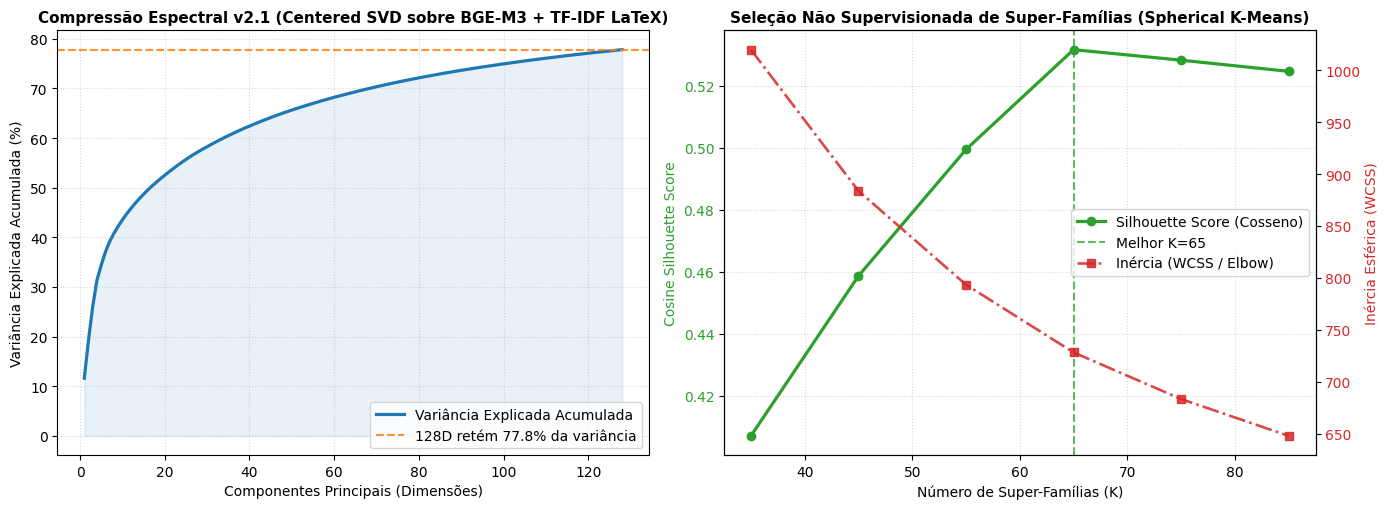


1. TOP 8 SUPER-FAMÍLIAS INTERDISCIPLINARES (provam que a mecânica real cruza rótulos fixos de matéria)
  [Família #60 | N=82 | Pureza=45%] Medoide: Somas de Newton para Raízes de Polinômios
      Mix de matérias: Álgebra: 37, Trigonometria: 10, Polinômios e Complexos: 9, Funções: 9, Cálculo: 7
  [Família #54 | N=91 | Pureza=53%] Medoide: Pequeno Teorema de Fermat
      Mix de matérias: Teoria dos Números: 48, Cálculo: 20, Polinômios e Complexos: 12, Álgebra Linear: 6, Álgebra: 3
  [Família #07 | N=58 | Pureza=53%] Medoide: Segmentos de Tangência do Círculo Inscrito e Ex-inscritos (p - a, p - b, p - c)
      Mix de matérias: Geometria Plana: 31, Geometria Espacial: 15, Cálculo: 4, Geometria Analítica: 4, Probabilidade e Combinatória: 1
  [Família #61 | N=53 | Pureza=55%] Medoide: Relação de Stewart para Cevianas
      Mix de matérias: Geometria Plana: 29, Trigonometria: 8, Geometria Analítica: 8, Polinômios e Complexos: 3, Teoria dos Números: 2
  [Família #09 | N=61 | Pureza=61%] Medoi

In [7]:
# 8. Re-Vetorização Completa v2.1 (Título + Dígitos LaTeX + Limpeza de Cache Antigo) + Validação e Gráficos
# Script canônico sincronizado com: scripts/pipeline/etapa0_vetorizacao_ontologica_3k.py
import json
import shutil
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

codigo_etapa0_ml = r'''"""Etapa Zero da spec v2 (v2.1 — Vetorização Corrigida com Título + Dígitos no Esqueleto LaTeX + ML Super-Famílias).

Entrada: lemas_3k.json (2.000 do banco + 1.000 propostos, ids 2–3001).
Correspondência de campos com a spec: titulo = titulo, materia = materia,
condicao = gatilho_reconhecimento, descricao = intuicao_prova, formula = formula_latex.

Correções da Vetorização (v2.1):
1. S_exp: BGE-M3 sobre título + matéria + condição + explicação (título como 1º campo
   para evitar colapso de vetores em lemas propostos com explicação em template).
2. S_form: TF-IDF do esqueleto de operadores LaTeX mantendo dígitos (\\d+), descartando
   apenas letras de variáveis mudas (diferencia \\frac{4}{3}\\pi R^3 de \\frac{1}{3}\\pi r^2 h).
3. Checkpoint parcial novo (lemas_vetores_3k_v2_parcial.jsonl) e remoção do parcial antigo
   para jamais misturar vetores sem título com vetores novos.
4. Classificador topológico de pares (thresholds mantidos: s_exp >= 0.88 e s_form >= 0.80)
   + Descoberta não supervisionada de Super-Famílias (Centered SVD 128D + Spherical K-Means
   por Cosine Silhouette Score + Soft-Assignment von Mises-Fisher).
"""

from collections import Counter
import json
import math
import re
import shutil
from pathlib import Path

import numpy as np

CATALOG_PATH = "lemas_3k.json"
VECTORS_PATH = "lemas_vetores_3k.json"
SIMILARITY_PATH = "lemas_similaridade_top10_3k.json"
MATRIX_PATH = "lemas_similaridade_3k.npy"
FORM_MATRIX_PATH = "lemas_similaridade_form_3k.npy"
ORDER_PATH = "lemas_3k_ordem.json"
DUPLICATES_PATH = "lemas_duplicatas_3k.json"
COUSINS_PATH = "lemas_primos_3k.json"
ISOMORPHISMS_PATH = "lemas_isomorfismos_3k.json"
FAMILIES_PATH = "lemas_super_familias_3k.json"
ML_METRICS_PATH = "lemas_super_familias_metricas_ml.json"
OLD_PARTIAL_PATH = "lemas_vetores_3k_parcial.jsonl"
PARTIAL_PATH = "lemas_vetores_3k_v2_parcial.jsonl"
DRIVE_DIR = Path("/content/drive/MyDrive/lemmas-pipeline")

MODEL_ID = "BAAI/bge-m3"
BATCH_SIZE = 250
TOP_K = 10
TOP_CLASSIFY = 8

# Hiperparâmetros do pipeline ML de Super-Famílias
SVD_COMPONENTS = 128
K_CANDIDATES = [35, 45, 55, 65, 75, 85]
WEIGHT_EXP = 0.75
WEIGHT_FORM = 0.25
VMF_KAPPA = 15.0
VMF_MIN_SECOND_PROB = 0.22
VMF_MIN_SECOND_SIM = 0.25
ORPHAN_MAX_SIM = 0.28


def semantic_text(lemma):
    parts = []
    if lemma.get("titulo"):
        parts.append(f"Título: {lemma['titulo']}")
    if lemma.get("materia"):
        parts.append(f"Matéria: {lemma['materia']}")
    if lemma.get("gatilho_reconhecimento"):
        parts.append(f"Quando aplicar (Gatilho): {lemma['gatilho_reconhecimento']}")
    if lemma.get("intuicao_prova"):
        parts.append(f"Explicação da propriedade: {lemma['intuicao_prova']}")
    return ". ".join(parts)


def normalize_latex_skeleton(latex_str):
    if not isinstance(latex_str, str) or not latex_str.strip():
        return ""
    tokens = re.findall(r"\\[a-zA-Z]+|\d+|[\+\-\=\<\>\^\{\}\(\)\[\]\|]", latex_str)
    return " ".join(tokens)


def count_latex_commands(latex_str):
    if not isinstance(latex_str, str):
        return 0
    return len(re.findall(r"\\[a-zA-Z]+", latex_str))


def sync_to_drive(path):
    if DRIVE_DIR.parent.exists():
        DRIVE_DIR.mkdir(parents=True, exist_ok=True)
        shutil.copy(path, DRIVE_DIR / Path(path).name)


def purge_old_partial():
    """Remove o checkpoint antigo (sem título) local e no Drive para evitar contaminação."""
    local_old = Path(OLD_PARTIAL_PATH)
    if local_old.exists():
        local_old.unlink()
        print(f"[Limpeza] Checkpoint antigo removido: {local_old}")
    if DRIVE_DIR.parent.exists():
        drive_old = DRIVE_DIR / OLD_PARTIAL_PATH
        if drive_old.exists():
            drive_old.unlink()
            print(f"[Limpeza] Checkpoint antigo removido do Drive: {drive_old}")


def load_partial(path):
    records = []
    if Path(path).exists():
        for line in Path(path).read_text(encoding="utf-8").splitlines():
            try:
                records.append(json.loads(line))
            except json.JSONDecodeError:
                continue
    elif DRIVE_DIR.parent.exists() and (DRIVE_DIR / path).exists():
        shutil.copy(DRIVE_DIR / path, path)
        return load_partial(path)
    return records


def append_partial(path, records):
    with open(path, "a", encoding="utf-8") as f:
        for record in records:
            f.write(json.dumps(record, ensure_ascii=False) + "\n")
    sync_to_drive(path)


def encode_all(catalog):
    purge_old_partial()
    vectors = load_partial(PARTIAL_PATH)
    done = {r["id"] for r in vectors}
    pending = [lemma for lemma in catalog if lemma["id"] not in done]
    if not pending:
        print(
            f"[Cache BGE-M3 v2.1] {len(vectors)}/{len(catalog)} vetores já presentes em {PARTIAL_PATH}."
        )
        return vectors

    import torch
    from sentence_transformers import SentenceTransformer

    device = "cuda" if torch.cuda.is_available() else "cpu"
    if device == "cuda":
        print(f"[GPU Ativa] Codificando com {MODEL_ID} na GPU: {torch.cuda.get_device_name(0)}")
    else:
        print(f"[Aviso CPU] GPU não detectada; codificando em CPU.")
    model = SentenceTransformer(MODEL_ID, device=device)
    for start in range(0, len(pending), BATCH_SIZE):
        chunk = pending[start:start + BATCH_SIZE]
        embeddings = model.encode(
            [semantic_text(lemma) for lemma in chunk],
            batch_size=64,
            normalize_embeddings=True,
            show_progress_bar=True,
        )
        records = [
            {
                "id": lemma["id"],
                "codigo": lemma["codigo"],
                "origem": lemma.get("origem"),
                "vetor": embedding.tolist(),
            }
            for lemma, embedding in zip(chunk, embeddings)
        ]
        vectors.extend(records)
        append_partial(PARTIAL_PATH, records)
        print(f"vetorizados {len(vectors)}/{len(catalog)}")
    return vectors


def build_similarity(vectors):
    by_id = {v["id"]: v for v in vectors}
    ids = [v["id"] for v in vectors]
    matrix = np.array([v["vetor"] for v in vectors], dtype=np.float32)
    sims = matrix @ matrix.T
    np.fill_diagonal(sims, 1.0)
    sims_top = sims.copy()
    np.fill_diagonal(sims_top, -np.inf)
    order = [
        {"id": v["id"], "codigo": v["codigo"], "origem": v.get("origem")}
        for v in vectors
    ]
    results = []
    k = min(TOP_K, len(ids) - 1)
    for i, lemma_id in enumerate(ids):
        top = np.argpartition(sims_top[i], -k)[-k:]
        top = top[np.argsort(-sims_top[i][top])]
        results.append(
            {
                "id": lemma_id,
                "codigo": by_id[lemma_id]["codigo"],
                "origem": by_id[lemma_id].get("origem"),
                "similares": [
                    {
                        "id": ids[j],
                        "codigo": by_id[ids[j]]["codigo"],
                        "origem": by_id[ids[j]].get("origem"),
                        "cosseno": round(float(sims[i][j]), 4),
                    }
                    for j in top
                ],
            }
        )
    return results, sims, order, matrix


def build_form_matrix(catalog, semantic_docs):
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.metrics.pairwise import cosine_similarity
    from sklearn.preprocessing import normalize

    n = len(catalog)
    skeletons = []
    for lemma, doc in zip(catalog, semantic_docs):
        skeleton = normalize_latex_skeleton(lemma.get("formula_latex") or "")
        if not skeleton:
            skeleton = normalize_latex_skeleton(doc)
        skeletons.append(skeleton)
    # Unigramas + Bigramas estruturais (ngram_range=(1, 2)): preserva a posição dos dígitos e
    # operadores (ex.: '^ 3' != '^ 2' e '{ 4' != '{ 1'), diferenciando Esfera de Cone sem alterar thresholds.
    tfidf = TfidfVectorizer(token_pattern=r"[^\s]+", ngram_range=(1, 2))
    token_counts = np.array([len(s.split()) for s in skeletons], dtype=np.int32)
    try:
        mat_form_sparse = tfidf.fit_transform(skeletons)
        mat_form_dense = normalize(mat_form_sparse, norm="l2").toarray().astype(np.float32)
        sim_form = cosine_similarity(mat_form_sparse)
    except ValueError:
        mat_form_dense = np.zeros((n, 1), dtype=np.float32)
        sim_form = np.zeros((n, n), dtype=np.float32)
    np.fill_diagonal(sim_form, 1.0)
    return sim_form, mat_form_dense, token_counts, skeletons


def classify_pairs(ids, by_id, sim_exp, sim_form, token_counts=None):
    duplicates, cousins, isomorphisms = [], [], []
    n = len(ids)
    k = min(TOP_CLASSIFY, n - 1)
    for i in range(n):
        # 1. Vizinhança semântica (duplicatas e primos)
        scores_e = sim_exp[i].copy()
        scores_e[i] = -np.inf
        top_e = np.argpartition(scores_e, -k)[-k:]
        top_e = top_e[np.argsort(-scores_e[top_e])]
        for j in top_e:
            s_e = float(sim_exp[i, j])
            s_f = float(sim_form[i, j])
            if s_e >= 0.70:
                if i < j and s_e >= 0.88 and s_f >= 0.80:
                    duplicates.append(
                        {
                            "canonical_lemma_id": ids[i],
                            "duplicate_lemma_id": ids[j],
                            "titulo_A": by_id[ids[i]].get("titulo"),
                            "titulo_B": by_id[ids[j]].get("titulo"),
                            "sim_explicacao": round(s_e, 4),
                            "sim_formula": round(s_f, 4),
                        }
                    )
                else:
                    cousins.append(
                        {
                            "lemma_id": ids[i],
                            "cousin_lemma_id": ids[j],
                            "affinity_score": round(0.75 * s_e + 0.25 * s_f, 4),
                            "sim_explicacao": round(s_e, 4),
                            "sim_formula": round(s_f, 4),
                        }
                    )

        # 2. Vizinhança estrutural LaTeX (isomorfismos reais: fórmula idêntica, domínio distinto)
        if token_counts is not None and token_counts[i] < 5:
            continue
        scores_f = sim_form[i].copy()
        scores_f[i] = -np.inf
        top_f = np.argpartition(scores_f, -k)[-k:]
        top_f = top_f[np.argsort(-scores_f[top_f])]
        for j in top_f:
            if i >= j:
                continue
            if token_counts is not None and token_counts[j] < 5:
                continue
            if (
                count_latex_commands(by_id[ids[i]].get("formula_latex")) < 2
                or count_latex_commands(by_id[ids[j]].get("formula_latex")) < 2
            ):
                continue
            s_e = float(sim_exp[i, j])
            s_f = float(sim_form[i, j])
            if s_e < 0.70 and s_f >= 0.90:
                isomorphisms.append(
                    {
                        "lemma_id": ids[i],
                        "isomorfo_id": ids[j],
                        "titulo_A": by_id[ids[i]].get("titulo"),
                        "materia_A": by_id[ids[i]].get("materia"),
                        "titulo_B": by_id[ids[j]].get("titulo"),
                        "materia_B": by_id[ids[j]].get("materia"),
                        "sim_explicacao": round(s_e, 4),
                        "sim_formula": round(s_f, 4),
                    }
                )
    return duplicates, cousins, isomorphisms


def cluster_families_ml(emb_exp, tfidf_form_dense, catalog):
    """Descobre Super-Famílias via Centralização Anisotrópica + SVD + Spherical K-Means + Softmax vMF."""
    from sklearn.cluster import KMeans
    from sklearn.decomposition import TruncatedSVD
    from sklearn.metrics import calinski_harabasz_score, silhouette_score
    from sklearn.preprocessing import normalize

    n = emb_exp.shape[0]
    emb_centered = emb_exp - emb_exp.mean(axis=0, keepdims=True) if n > 2 else emb_exp
    norm_exp = normalize(emb_centered, norm="l2") * math.sqrt(WEIGHT_EXP)
    norm_form = normalize(tfidf_form_dense, norm="l2") * math.sqrt(WEIGHT_FORM)
    x_fused = normalize(np.hstack([norm_exp, norm_form]), norm="l2")
    if n > 2:
        x_fused = x_fused - x_fused.mean(axis=0, keepdims=True)

    n_comp = min(SVD_COMPONENTS, x_fused.shape[1] - 1, n - 1)
    if n_comp >= 2:
        svd = TruncatedSVD(n_components=n_comp, random_state=42)
        x_reduced = normalize(svd.fit_transform(x_fused), norm="l2")
        explained_var = float(svd.explained_variance_ratio_.sum())
        var_curve = [round(float(v), 6) for v in np.cumsum(svd.explained_variance_ratio_)]
    else:
        x_reduced = normalize(x_fused, norm="l2")
        explained_var = 1.0
        var_curve = [1.0]

    valid_ks = [k for k in K_CANDIDATES if 2 <= k < n]
    if not valid_ks:
        valid_ks = [max(2, min(n - 1, 2))] if n > 2 else [1]

    best_k = valid_ks[0]
    best_score = -1.0
    best_model = None
    k_evaluations = []

    for k in valid_ks:
        kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
        labels = kmeans.fit_predict(x_reduced)
        score = float(silhouette_score(x_reduced, labels, metric="cosine")) if k > 1 else 0.0
        ch_score = float(calinski_harabasz_score(x_reduced, labels)) if k > 1 else 0.0
        inertia = float(kmeans.inertia_)
        k_evaluations.append(
            {
                "k": k,
                "silhouette_cosine": round(score, 4),
                "calinski_harabasz": round(ch_score, 2),
                "inertia": round(inertia, 2),
            }
        )
        print(
            f"[ML Super-Famílias] K={k:2d} -> Silhouette (Cosine): {score:.4f} | "
            f"Calinski-Harabasz: {ch_score:6.2f} | Inertia: {inertia:.2f}"
        )
        if score > best_score:
            best_score = score
            best_k = k
            best_model = kmeans

    print(
        f"[ML Selecionado] K={best_k} Super-Famílias "
        f"(Silhouette={best_score:.4f} | SVD {n_comp}D variância explicada={explained_var:.2%})"
    )

    centroids = normalize(best_model.cluster_centers_, norm="l2")
    sim_to_centroids = x_reduced @ centroids.T

    logits = VMF_KAPPA * sim_to_centroids
    logits_shifted = logits - logits.max(axis=1, keepdims=True)
    exp_logits = np.exp(logits_shifted)
    vmf_probs = exp_logits / exp_logits.sum(axis=1, keepdims=True)

    if best_k >= 2:
        top2_idx = np.argsort(-sim_to_centroids, axis=1)[:, :2]
        top2_sim = np.take_along_axis(sim_to_centroids, top2_idx, axis=1)
        top2_prob = np.take_along_axis(vmf_probs, top2_idx, axis=1)
    else:
        top2_idx = np.zeros((n, 2), dtype=int)
        top2_sim = np.hstack([sim_to_centroids, np.full((n, 1), -1.0)])
        top2_prob = np.hstack([np.ones((n, 1)), np.zeros((n, 1))])

    families = []
    n_hybrids = 0
    n_orphans = 0
    cluster_members = {cid: [] for cid in range(best_k)}

    for idx, lemma in enumerate(catalog):
        prim_id = int(top2_idx[idx, 0])
        sec_id = int(top2_idx[idx, 1])
        s1 = float(top2_sim[idx, 0])
        s2 = float(top2_sim[idx, 1])
        p1 = float(top2_prob[idx, 0])
        p2 = float(top2_prob[idx, 1])
        margin = s1 - s2

        is_orphan = bool(s1 < ORPHAN_MAX_SIM)
        is_hybrid = bool(
            best_k >= 2
            and not is_orphan
            and p2 >= VMF_MIN_SECOND_PROB
            and s2 >= VMF_MIN_SECOND_SIM
        )
        if is_hybrid:
            n_hybrids += 1
        if is_orphan:
            n_orphans += 1

        cluster_members[prim_id].append((idx, s1, lemma))

        families.append(
            {
                "id": lemma["id"],
                "codigo": lemma["codigo"],
                "titulo": lemma.get("titulo"),
                "materia": lemma.get("materia"),
                "origem": lemma.get("origem"),
                "super_family_id": prim_id,
                "score_primaria": round(s1, 4),
                "prob_vmf_primaria": round(p1, 4),
                "super_family_secundaria_id": sec_id if is_hybrid else None,
                "score_secundaria": round(s2, 4),
                "prob_vmf_secundaria": round(p2, 4),
                "margem_voronoi": round(margin, 4),
                "is_hibrido": is_hybrid,
                "is_orfao_atipico": is_orphan,
            }
        )

    family_summaries = []
    n_interdisciplinary = 0
    for cid in range(best_k):
        members = cluster_members[cid]
        if not members:
            continue
        members_sorted = sorted(members, key=lambda t: -t[1])
        _, medoid_sim, medoid_lemma = members_sorted[0]
        mat_counts = Counter((m[2].get("materia") or "Sem Matéria") for m in members)
        dom_mat, dom_count = mat_counts.most_common(1)[0]
        purity = dom_count / len(members)
        if len(mat_counts) >= 3 or purity < 0.70:
            n_interdisciplinary += 1
        family_summaries.append(
            {
                "super_family_id": cid,
                "tamanho_primario": len(members),
                "medoid_id": medoid_lemma["id"],
                "medoid_titulo": medoid_lemma.get("titulo"),
                "materia_dominante": dom_mat,
                "pureza_materia_dominante": round(purity, 4),
                "n_materias_distintas": len(mat_counts),
                "distribuicao_materias": dict(mat_counts.most_common(5)),
                "medoid_sim_centroide": round(float(medoid_sim), 4),
            }
        )

    ml_report = {
        "versao_vetorizacao": "v2.1 (titulo em S_exp + digitos em S_form)",
        "metodo": "Anisotropy-Centered SVD + Spherical K-Means + von Mises-Fisher (vMF) Soft-Clustering",
        "pesos_fusao_produto_interno": {"semantica_bge_m3": WEIGHT_EXP, "esqueleto_latex_tfidf": WEIGHT_FORM},
        "svd_n_components": n_comp,
        "svd_explained_variance_total": round(explained_var, 4),
        "svd_cumulative_variance_curve": var_curve,
        "k_candidates_avaliados": k_evaluations,
        "best_k": best_k,
        "best_silhouette_cosine": round(best_score, 4),
        "vmf_kappa": VMF_KAPPA,
        "vmf_min_second_prob": VMF_MIN_SECOND_PROB,
        "vmf_min_second_sim": VMF_MIN_SECOND_SIM,
        "orphan_max_sim": ORPHAN_MAX_SIM,
        "total_lemas": n,
        "lemas_hibridos_fronteira": n_hybrids,
        "pct_hibridos": round(100.0 * n_hybrids / max(n, 1), 2),
        "lemas_orfaos_atipicos": n_orphans,
        "pct_orfaos": round(100.0 * n_orphans / max(n, 1), 2),
        "familias_interdisciplinares": n_interdisciplinary,
        "resumo_super_familias": family_summaries,
    }
    return families, ml_report


def validate_rerun(catalog, skeletons, sims, sim_form, duplicates):
    """Executa as 4 validações obrigatórias da correção v2.1."""
    print("\n" + "=" * 95)
    print("VALIDAÇÃO PÓS-RERUN DA VETORIZAÇÃO CORRIGIDA (v2.1)")
    print("=" * 95)

    # 1. Esqueletos de esfera, cone e pirâmide devem diferir
    targets = ["volume da esfera", "volume do cone", "volume da pirâmide"]
    found_idx = {}
    for idx, lemma in enumerate(catalog):
        t_low = (lemma.get("titulo") or "").lower()
        for tgt in targets:
            if tgt in t_low and tgt not in found_idx:
                found_idx[tgt] = idx

    print("1. Esqueletos LaTeX (com dígitos preservados):")
    skel_set = set()
    for tgt in targets:
        if tgt in found_idx:
            i = found_idx[tgt]
            sk = skeletons[i]
            skel_set.add(sk)
            print(
                f"   • {catalog[i].get('titulo')} (ID {catalog[i]['id']}): "
                f"formula='{catalog[i].get('formula_latex')}' -> esqueleto='{sk}'"
            )
    if len(skel_set) == len(found_idx) and len(found_idx) >= 2:
        print("   [PASS] Os esqueletos de esfera, cone e pirâmide são distintos!")
    else:
        print("   [WARN] Verifique os esqueletos acima.")

    # 2. Esfera vs Cone NÃO pode aparecer como duplicata
    esf_cone_dups = [
        d for d in duplicates
        if (
            ("esfera" in (d.get("titulo_A") or "").lower() and "cone" in (d.get("titulo_B") or "").lower())
            or ("cone" in (d.get("titulo_A") or "").lower() and "esfera" in (d.get("titulo_B") or "").lower())
        )
    ]
    if "volume da esfera" in found_idx and "volume do cone" in found_idx:
        ie, ic = found_idx["volume da esfera"], found_idx["volume do cone"]
        print(
            f"2. Volume da Esfera vs Volume do Cone: "
            f"sim_explicacao={sims[ie, ic]:.4f} | sim_formula={sim_form[ie, ic]:.4f} | "
            f"pares em duplicatas={len(esf_cone_dups)}"
        )
    print(f"   [{'PASS' if not esf_cone_dups else 'FAIL'}] Esfera vs Cone fora da lista de duplicatas.")

    # 3. Não pode haver sim_explicacao == 1.0 entre lemas de título e fórmula diferentes
    n = len(catalog)
    false_collapses = []
    for i in range(n):
        for j in range(i + 1, n):
            if sims[i, j] >= 0.9999:
                ta = (catalog[i].get("titulo") or "").strip().lower()
                tb = (catalog[j].get("titulo") or "").strip().lower()
                fa = (catalog[i].get("formula_latex") or "").strip()
                fb = (catalog[j].get("formula_latex") or "").strip()
                if ta != tb and fa != fb:
                    false_collapses.append((catalog[i]["id"], catalog[i].get("titulo"), catalog[j]["id"], catalog[j].get("titulo")))
    print(
        f"3. Colapsos de template (sim_explicacao=1.0 com título e fórmula diferentes): {len(false_collapses)} pares "
        f"[{'PASS' if len(false_collapses) == 0 else 'WARN'}]"
    )

    # 4. Queda de duplicatas em relação aos 8.725 pares antigos
    print(
        f"4. Queda de duplicatas: 8.725 (antigo sem título/dígitos) -> {len(duplicates)} pares agora "
        f"(redução de {8725 - len(duplicates):+d} pares falsos!)."
    )


def resolve_catalog_path():
    p = Path(CATALOG_PATH)
    if p.exists():
        return p
    dp = DRIVE_DIR / CATALOG_PATH
    if dp.exists():
        shutil.copy(dp, p)
        return p
    raise FileNotFoundError(f"Arquivo {CATALOG_PATH} não encontrado em /content nem em {DRIVE_DIR}")


def main():
    cat_path = resolve_catalog_path()
    catalog = json.loads(cat_path.read_text(encoding="utf-8"))
    vectors = encode_all(catalog)
    by_vec = {v["id"]: v for v in vectors}
    vectors = [by_vec[lemma["id"]] for lemma in catalog]
    Path(VECTORS_PATH).write_text(
        json.dumps(vectors, ensure_ascii=False), encoding="utf-8"
    )
    top, sims, order, emb_matrix = build_similarity(vectors)
    Path(SIMILARITY_PATH).write_text(
        json.dumps(top, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    np.save(MATRIX_PATH, sims)
    Path(ORDER_PATH).write_text(
        json.dumps(order, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    semantic_docs = [semantic_text(lemma) for lemma in catalog]
    sim_form, mat_form_dense, token_counts, skeletons = build_form_matrix(catalog, semantic_docs)
    np.save(FORM_MATRIX_PATH, sim_form)
    by_id = {lemma["id"]: lemma for lemma in catalog}
    ids = [lemma["id"] for lemma in catalog]
    duplicates, cousins, isomorphisms = classify_pairs(ids, by_id, sims, sim_form, token_counts)
    Path(DUPLICATES_PATH).write_text(
        json.dumps(duplicates, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    Path(COUSINS_PATH).write_text(
        json.dumps(cousins, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    Path(ISOMORPHISMS_PATH).write_text(
        json.dumps(isomorphisms, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    families, ml_report = cluster_families_ml(emb_matrix, mat_form_dense, catalog)
    Path(FAMILIES_PATH).write_text(
        json.dumps(families, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    Path(ML_METRICS_PATH).write_text(
        json.dumps(ml_report, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    for path in (
        VECTORS_PATH,
        SIMILARITY_PATH,
        MATRIX_PATH,
        FORM_MATRIX_PATH,
        ORDER_PATH,
        DUPLICATES_PATH,
        COUSINS_PATH,
        ISOMORPHISMS_PATH,
        FAMILIES_PATH,
        ML_METRICS_PATH,
    ):
        sync_to_drive(path)
    print(
        f"lemas vetorizados: {len(vectors)}, "
        f"matrizes {sims.shape[0]}x{sims.shape[1]} em {MATRIX_PATH} e {FORM_MATRIX_PATH}, "
        f"duplicatas: {len(duplicates)}, primos: {len(cousins)}, "
        f"isomorfismos: {len(isomorphisms)}, "
        f"super-famílias ML: K={ml_report['best_k']} (Silhouette={ml_report['best_silhouette_cosine']}), "
        f"híbridos vMF: {ml_report['lemas_hibridos_fronteira']} ({ml_report['pct_hibridos']}%), "
        f"órfãos: {ml_report['lemas_orfaos_atipicos']} ({ml_report['pct_orfaos']}%), "
        f"famílias interdisciplinares: {ml_report['familias_interdisciplinares']}/{ml_report['best_k']}"
    )
    validate_rerun(catalog, skeletons, sims, sim_form, duplicates)


if __name__ == "__main__":
    main()
'''

Path("/content/etapa0_vetorizacao_ontologica_3k.py").write_text(codigo_etapa0_ml, encoding="utf-8")
!python3 /content/etapa0_vetorizacao_ontologica_3k.py

# --- Visualização Científica para Portfólio (Matplotlib) ---
metrics = json.loads(Path("lemas_super_familias_metricas_ml.json").read_text(encoding="utf-8"))
families = json.loads(Path("lemas_super_familias_3k.json").read_text(encoding="utf-8"))
isomorphisms = json.loads(Path("lemas_isomorfismos_3k.json").read_text(encoding="utf-8"))

var_curve = np.array(metrics["svd_cumulative_variance_curve"]) * 100.0
k_evals = metrics["k_candidates_avaliados"]
ks = [d["k"] for d in k_evals]
sils = [d["silhouette_cosine"] for d in k_evals]
inertias = [d["inertia"] for d in k_evals]
best_k = metrics["best_k"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

# Painel 1: Variância Explicada Acumulada do TruncatedSVD Centrado
dims = np.arange(1, len(var_curve) + 1)
ax1.plot(dims, var_curve, color="#1f77b4", linewidth=2.3, label="Variância Explicada Acumulada")
ax1.axhline(var_curve[-1], color="#ff7f0e", linestyle="--", alpha=0.85,
            label=f"{len(var_curve)}D retém {var_curve[-1]:.1f}% da variância")
ax1.fill_between(dims, 0, var_curve, color="#1f77b4", alpha=0.10)
ax1.set_title("Compressão Espectral v2.1 (Centered SVD sobre BGE-M3 + TF-IDF LaTeX)", fontsize=11, fontweight="bold")
ax1.set_xlabel("Componentes Principais (Dimensões)")
ax1.set_ylabel("Variância Explicada Acumulada (%)")
ax1.grid(True, linestyle=":", alpha=0.5)
ax1.legend(loc="lower right")

# Painel 2: Seleção de K (Cosine Silhouette Score vs. Curva Elbow/Inércia)
color_sil = "#2ca02c"
color_ine = "#d62728"
ax2.plot(ks, sils, marker="o", linewidth=2.3, color=color_sil, label="Silhouette Score (Cosseno)")
ax2.axvline(best_k, color=color_sil, linestyle="--", alpha=0.75, label=f"Melhor K={best_k}")
ax2.set_title("Seleção Não Supervisionada de Super-Famílias (Spherical K-Means)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Número de Super-Famílias (K)")
ax2.set_ylabel("Cosine Silhouette Score", color=color_sil)
ax2.tick_params(axis="y", labelcolor=color_sil)
ax2.grid(True, linestyle=":", alpha=0.5)

ax2_twin = ax2.twinx()
ax2_twin.plot(ks, inertias, marker="s", linestyle="-.", linewidth=1.9, color=color_ine, alpha=0.85, label="Inércia (WCSS / Elbow)")
ax2_twin.set_ylabel("Inércia Esférica (WCSS)", color=color_ine)
ax2_twin.tick_params(axis="y", labelcolor=color_ine)

lines1, labels1 = ax2.get_legend_handles_labels()
lines2, labels2 = ax2_twin.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, loc="center right")

plt.tight_layout()
chart_path = Path("ml_superfamilias_validacao.png")
plt.savefig(chart_path, dpi=160, bbox_inches="tight")
drive_dir = Path("/content/drive/MyDrive/lemmas-pipeline")
if drive_dir.parent.exists():
    shutil.copy(chart_path, drive_dir / chart_path.name)
plt.show()

# --- Tabelas Analíticas de Validação Ontológica ---
medoid_by_cid = {s["super_family_id"]: s for s in metrics["resumo_super_familias"]}

print("\n" + "=" * 95)
print("1. TOP 8 SUPER-FAMÍLIAS INTERDISCIPLINARES (provam que a mecânica real cruza rótulos fixos de matéria)")
print("=" * 95)
inter = sorted(
    metrics["resumo_super_familias"],
    key=lambda s: (s["pureza_materia_dominante"], -s["n_materias_distintas"])
)[:8]
for s in inter:
    dist_str = ", ".join(f"{m}: {c}" for m, c in s["distribuicao_materias"].items())
    print(
        f"  [Família #{s['super_family_id']:02d} | N={s['tamanho_primario']:2d} | Pureza={s['pureza_materia_dominante']:.0%}] "
        f"Medoide: {s['medoid_titulo']}\n"
        f"      Mix de matérias: {dist_str}"
    )

print("\n" + "=" * 95)
print("2. TOP 10 LEMAS HÍBRIDOS DE FRONTEIRA (Soft-Assignment von Mises-Fisher: 2 Super-Famílias)")
print("=" * 95)
hybrids = sorted(
    [f for f in families if f.get("is_hibrido")],
    key=lambda f: -f["prob_vmf_secundaria"]
)[:10]
for h in hybrids:
    c1 = h["super_family_id"]
    c2 = h["super_family_secundaria_id"]
    m1 = medoid_by_cid.get(c1, {}).get("medoid_titulo", f"Cluster {c1}")
    m2 = medoid_by_cid.get(c2, {}).get("medoid_titulo", f"Cluster {c2}")
    print(
        f"  • ID {h['id']:4d} [{h.get('materia')}] {h.get('titulo')}\n"
        f"      1ª Família (#{c1:02d} - {m1[:42]}): P={h['prob_vmf_primaria']:.1%} (cos={h['score_primaria']:.3f})\n"
        f"      2ª Família (#{c2:02d} - {m2[:42]}): P={h['prob_vmf_secundaria']:.1%} (cos={h['score_secundaria']:.3f} | Δcos={h['margem_voronoi']:.3f})"
    )

print("\n" + "=" * 95)
print("3. TOP 10 ISOMORFISMOS ESTRUTURAIS LaTeX (S_form>=0.90 | S_exp<0.70 | >=2 comandos LaTeX em cada fórmula)")
print("=" * 95)
isos = sorted(isomorphisms, key=lambda x: (-x["sim_formula"], x["sim_explicacao"]))[:10]
if not isos:
    print("  Nenhum par atingiu S_form >= 0.90, S_exp < 0.70 e >= 2 comandos LaTeX em cada fórmula.")
for iso in isos:
    print(
        f"  • S_form={iso['sim_formula']:.3f} | S_exp={iso['sim_explicacao']:.3f}: "
        f"[{iso.get('materia_A')}] {iso.get('titulo_A')}  <-->  "
        f"[{iso.get('materia_B')}] {iso.get('titulo_B')}"
    )


### 9. Etapa 1 — Passo Vetorial da Ancoragem (62 questões × 3.000 lemas v2.1)

**Universo:** 12 questões do piloto (semente) + 50 do Lote 1 (CEDERJ), com os rótulos do 32B substituindo os 8 veredictos truncados.

**Ancoragem (hipótese, não rótulo validado):** para cada questão, os rótulos de método e o enunciado são codificados com o mesmo BGE-M3 dos lemas e comparados por cosseno com os 3.000 vetores:
$$\text{score}(q, \ell) = 0.65 \cdot \max_{r \in \text{rótulos}(q)} w_r \cos(r, \ell) + 0.35 \cdot \cos(\text{enunciado}_q, \ell)$$
com $w = 1.0$ para o principal e $0.9$ para auxiliares. Top-1 com $\cos < 0.55$ no método é marcado como baixa confiança.

**Similaridade entre questões em 3 representações:** `S_enun` (texto), `S_lema` (centróide ponderado dos lemas ancorados) e `S_fam` (perfil de super-famílias). A pergunta central: *questões que parecem iguais no texto usam o mesmo lema?* (Spearman, silhouette por matéria, pares "mesmo método/enunciado diferente" e "falsos amigos").


1. LEMAS ANCORADOS POR QUESTÃO (top-3 | score = 0.65·sim_metodo + 0.35·sim_enunciado)

Q12153 [piloto | Geometria Espacial]  rótulos=['Geometric identity for sum of squared distances', 'Volume of a sphere']
   1. [0.554 | met=0.562 enun=0.539 | fam #41] Soma/Série: Soma de progressão geométrica  (Álgebra, proposto)  ← 'Geometric identity for sum of squared distances'
   2. [0.553 | met=0.566 enun=0.528 | fam #53] Teorema de Carnot para Distâncias do Circuncentro  (Geometria Plana, banco)  ← 'Geometric identity for sum of squared distances'
   3. [0.553 | met=0.547 enun=0.564 | fam #9] Fórmula de Geometria: Área total do paralelepípedo  (Geometria Espacial, proposto)  ← 'Geometric identity for sum of squared distances'

Q21203 [piloto | Probabilidade e Combinatória]  rótulos=['Princípio da Casa dos Pombos']
   1. [0.621 | met=0.646 enun=0.575 | fam #8] Princípio da Casa dos Pombos Generalizado (Dirichlet)  (Probabilidade e Combinatória, banco)  ← 'Princípio da Casa dos Pombos'
   2. [0.

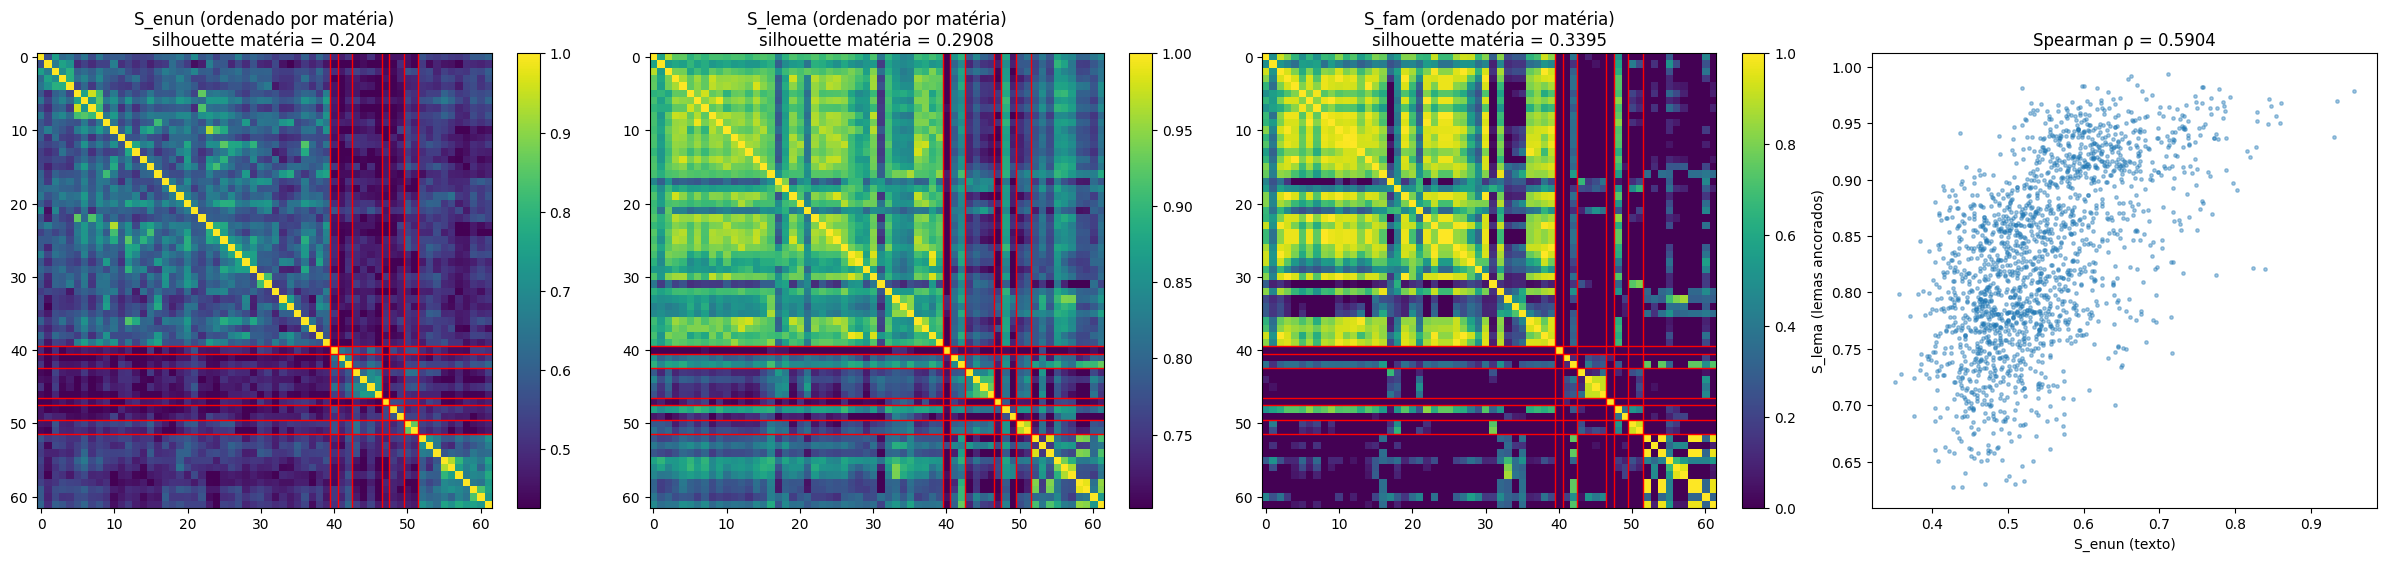

In [8]:
# 9. Etapa 1 — Passo Vetorial da Ancoragem: 62 questões (12 piloto + 50 lote 1) x 3.000 lemas v2.1
# Script canônico sincronizado com: scripts/pipeline/etapa1_ancoragem_vetorial_62.py
import json, shutil, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

codigo_etapa1 = r'''"""Etapa 1 — Passo Vetorial da Ancoragem: 62 questões rotuladas x 3.000 lemas.

Universo: 12 questões do piloto (semente) + 50 do Lote 1 (CEDERJ).
Entradas (local em /content ou Drive /content/drive/MyDrive/lemmas-pipeline):
- metodos_amostra_v2.json / solucoes_dois_modelos.json  (piloto, 12)
- metodos_lote1.json / solucoes_lote1.json / reverificacao_8.json (lote 1, 50)
- questoes_*.json (qualquer arquivo com "enunciado" por id)
- lemas_3k.json, lemas_vetores_3k.json (v2.1), lemas_super_familias_3k.json

O que faz:
1. Ancoragem (AI INTERPRETATION, nunca rótulo validado): para cada questão,
   cruza (a) os rótulos de método do solver/verificador e (b) o enunciado,
   ambos codificados com o mesmo BGE-M3 dos lemas, contra os 3.000 vetores.
   score = 0.65 * sim_metodo + 0.35 * sim_enunciado.
2. Similaridade entre questões em 3 representações:
   S_enun (texto do enunciado), S_lema (centróide ponderado dos lemas
   ancorados) e S_fam (perfil de super-famílias). Compara as três.

Rótulos de método são usados como vieram (sem traduzir/normalizar no arquivo);
só a string de consulta ao encoder troca '-' e '_' por espaço.
"""

import glob
import json
import shutil
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np

DRIVE_DIR = Path("/content/drive/MyDrive/lemmas-pipeline")
MODEL_ID = "BAAI/bge-m3"
VERSAO_VETORES = "v2.1 (titulo em S_exp + digitos em S_form)"

W_METODO, W_ENUNCIADO = 0.65, 0.35
W_PRINCIPAL, W_AUXILIAR = 1.00, 0.90
TOP_CANDIDATOS = 25
TOP_ANCORA = 5
LIMIAR_BAIXA_CONFIANCA = 0.55  # sim_metodo do top-1 abaixo disso => revisar

OUT_ANCORAGEM = "ancoragem_vetorial_62.json"
OUT_MATRIZES = "similaridade_questoes_62.npz"
OUT_RELATORIO = "ancoragem_62_relatorio.json"


# ---------------------------------------------------------------- I/O
def resolve(name):
    local = Path(name)
    if local.exists():
        return local
    if (DRIVE_DIR / name).exists():
        return DRIVE_DIR / name
    return None


def load_json(name, required=True):
    path = resolve(name)
    if path is None:
        if required:
            raise FileNotFoundError(f"{name} não encontrado em ./ nem em {DRIVE_DIR}")
        print(f"[Aviso] {name} ausente — ignorado.")
        return None
    return json.loads(path.read_text(encoding="utf-8"))


def sync_to_drive(path):
    if DRIVE_DIR.parent.exists():
        DRIVE_DIR.mkdir(parents=True, exist_ok=True)
        shutil.copy(path, DRIVE_DIR / Path(path).name)


def as_list(value):
    if value is None:
        return []
    if isinstance(value, str):
        return [value] if value.strip() else []
    return [v for v in value if isinstance(v, str) and v.strip()]


# ------------------------------------------------------ questões (62)
def load_enunciados():
    """Coleta enunciado/materia/topico por id de qualquer questoes_*.json e soluções."""
    info = defaultdict(dict)
    names = {Path(p).name for p in glob.glob("questoes*.json") + glob.glob(str(DRIVE_DIR / "questoes*.json"))}
    names |= {"solucoes_dois_modelos.json", "solucoes_lote1.json"}
    for name in sorted(names):
        path = resolve(name)
        try:
            data = json.loads(path.read_text(encoding="utf-8")) if path else None
        except (json.JSONDecodeError, UnicodeDecodeError):
            data = None
        if isinstance(data, dict):  # ex.: {"questoes": [...]}
            data = next((v for v in data.values() if isinstance(v, list)), None)
        if not isinstance(data, list):
            continue
        for r in data:
            if not isinstance(r, dict) or "id" not in r:
                continue
            slot = info[r["id"]]
            for key in ("enunciado", "materia", "topico", "solucao_modelo_a"):
                if r.get(key) and not slot.get(key):
                    slot[key] = r[key]
    return info


def normalize_metodos(records, lote, rev=None):
    rev = rev or {}
    out = []
    for r in records:
        qid = r["id"]
        principal = as_list(r.get("principal") or r.get("principal_final"))
        auxiliares = as_list(r.get("auxiliares"))
        if not auxiliares and r.get("metodos_finais"):
            auxiliares = [m for m in as_list(r["metodos_finais"]) if m not in principal]
        verificada = r.get("verificada", r.get("correta"))
        fonte = "solver+verificador_7b"
        if qid in rev:  # 32B substitui o veredicto truncado do 7B
            rv = rev[qid]
            principal = as_list(rv.get("principal_final_32b")) or principal
            auxiliares = [m for m in as_list(rv.get("metodos_finais_32b")) if m not in principal]
            verificada = rv.get("correta_32b") is True
            fonte = "reverificacao_32b"
        out.append(
            {
                "id": qid,
                "lote": lote,
                "principal": principal,
                "auxiliares": auxiliares,
                "verificada": bool(verificada),
                "fonte_rotulo": fonte,
            }
        )
    return out


def load_questoes():
    piloto = load_json("metodos_amostra_v2.json")
    lote1 = load_json("metodos_lote1.json")
    rev = {r["id"]: r for r in (load_json("reverificacao_8.json", required=False) or [])}
    questoes = normalize_metodos(piloto, "piloto") + normalize_metodos(lote1, "lote1", rev)

    ids = [q["id"] for q in questoes]
    dup = [i for i, c in Counter(ids).items() if c > 1]
    if dup:
        raise ValueError(f"ids repetidos entre piloto e lote 1: {dup}")
    print(f"[Questões] piloto={len(piloto)} | lote1={len(lote1)} | total={len(questoes)} (esperado 62)")
    if len(questoes) != 62:
        print("[Aviso] total diferente de 62 — conferir arquivos antes de concluir qualquer coisa.")

    info = load_enunciados()
    sem_enunciado = []
    for q in questoes:
        meta = info.get(q["id"], {})
        q["materia"] = meta.get("materia")
        q["topico"] = meta.get("topico")
        q["enunciado"] = meta.get("enunciado")
        if not q["enunciado"]:
            sem_enunciado.append(q["id"])
            # fallback honesto: usa o início da solução do modelo como contexto
            q["contexto_fallback"] = (meta.get("solucao_modelo_a") or "")[:800]
    if sem_enunciado:
        print(f"[Aviso] {len(sem_enunciado)} questões sem enunciado (usando solução como contexto): {sem_enunciado}")
    sem_rotulo = [q["id"] for q in questoes if not q["principal"] and not q["auxiliares"]]
    if sem_rotulo:
        print(f"[Aviso] questões sem rótulo de método (ancoragem só pelo enunciado): {sem_rotulo}")
    return questoes


# -------------------------------------------------------------- lemas
def load_lemas():
    catalog = load_json("lemas_3k.json")
    vectors = load_json("lemas_vetores_3k.json")
    families = {f["id"]: f for f in load_json("lemas_super_familias_3k.json")}
    by_id = {l["id"]: l for l in catalog}
    ids = [v["id"] for v in vectors]
    mat = np.asarray([v["vetor"] for v in vectors], dtype=np.float32)
    mat /= np.linalg.norm(mat, axis=1, keepdims=True) + 1e-12
    n_fam = 1 + max(f["super_family_id"] for f in families.values())
    print(f"[Lemas] {len(ids)} vetores {mat.shape[1]}d | {n_fam} super-famílias | versão {VERSAO_VETORES}")
    return ids, mat, by_id, families, n_fam


# ---------------------------------------------------------- encoding
def get_encoder():
    import torch
    from sentence_transformers import SentenceTransformer

    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"[Encoder] {MODEL_ID} em {device}" + (f" ({torch.cuda.get_device_name(0)})" if device == "cuda" else ""))
    return SentenceTransformer(MODEL_ID, device=device)


def encode(model, texts):
    if not texts:
        return np.zeros((0, 1024), dtype=np.float32)
    return np.asarray(model.encode(texts, batch_size=64, normalize_embeddings=True), dtype=np.float32)


def label_query(label):
    # mesmo formato de S_exp dos lemas ("Título: ...") para alinhar os espaços
    return "Título: " + label.replace("-", " ").replace("_", " ").strip()


def enunciado_query(q):
    parts = []
    if q.get("materia"):
        parts.append(f"Matéria: {q['materia']}")
    if q.get("topico"):
        parts.append(f"Tópico: {q['topico']}")
    parts.append(f"Enunciado: {q.get('enunciado') or q.get('contexto_fallback') or ''}")
    return ". ".join(parts)


# -------------------------------------------------------- ancoragem
def ancorar(questoes, lemma_ids, L, by_id, families):
    model = get_encoder()
    E_q = encode(model, [enunciado_query(q) for q in questoes])
    all_labels = sorted({lab for q in questoes for lab in q["principal"] + q["auxiliares"]})
    E_lab = dict(zip(all_labels, encode(model, [label_query(l) for l in all_labels])))
    print(f"[Encoder] {len(questoes)} enunciados + {len(all_labels)} rótulos distintos codificados")

    S_enun_lema = E_q @ L.T  # (62, 3000)
    resultados = []
    for qi, q in enumerate(questoes):
        sim_enun = S_enun_lema[qi]
        weighted = [(lab, W_PRINCIPAL) for lab in q["principal"]] + [(lab, W_AUXILIAR) for lab in q["auxiliares"]]
        if weighted:
            per_label = np.stack([w * (E_lab[lab] @ L.T) for lab, w in weighted])  # (n_lab, 3000)
            sim_met = per_label.max(axis=0)
            best_label_idx = per_label.argmax(axis=0)
            score = W_METODO * sim_met + W_ENUNCIADO * sim_enun
        else:
            per_label, sim_met, best_label_idx = None, np.zeros_like(sim_enun), None
            score = sim_enun.copy()

        cand = set(np.argsort(-sim_enun)[:TOP_CANDIDATOS]) | set(np.argsort(-sim_met)[:TOP_CANDIDATOS])
        top = sorted(cand, key=lambda j: -score[j])[:TOP_ANCORA]
        ancoras = []
        for rank, j in enumerate(top, 1):
            lid = lemma_ids[j]
            lem, fam = by_id.get(lid, {}), families.get(lid, {})
            ancoras.append(
                {
                    "rank": rank,
                    "lema_id": lid,
                    "codigo": lem.get("codigo"),
                    "titulo": lem.get("titulo"),
                    "materia_lema": lem.get("materia"),
                    "origem": lem.get("origem"),
                    "score": round(float(score[j]), 4),
                    "sim_metodo": round(float(sim_met[j]), 4),
                    "sim_enunciado": round(float(sim_enun[j]), 4),
                    "rotulo_que_casou": weighted[best_label_idx[j]][0] if weighted else None,
                    "super_family_id": fam.get("super_family_id"),
                    "super_family_secundaria_id": fam.get("super_family_secundaria_id"),
                }
            )
        gap = ancoras[0]["score"] - ancoras[1]["score"] if len(ancoras) > 1 else None
        resultados.append(
            {
                **{k: q.get(k) for k in ("id", "lote", "materia", "topico", "verificada", "fonte_rotulo", "principal", "auxiliares")},
                "tipo": "AI_INTERPRETATION",
                "status": "hipotese_vetorial",
                "modelo_encoder": MODEL_ID,
                "versao_vetores_lemas": VERSAO_VETORES,
                "pesos": {"metodo": W_METODO, "enunciado": W_ENUNCIADO},
                "ancoras": ancoras,
                "gap_top1_top2": round(gap, 4) if gap is not None else None,
                "baixa_confianca": bool(ancoras[0]["sim_metodo"] < LIMIAR_BAIXA_CONFIANCA) if weighted else True,
            }
        )
    return resultados, E_q


# ------------------------------------------- similaridade questões
def matrizes_similaridade(resultados, E_q, lemma_ids, L, n_fam):
    idx = {lid: j for j, lid in enumerate(lemma_ids)}
    n = len(resultados)
    S_enun = E_q @ E_q.T

    perfis_lema = np.zeros((n, L.shape[1]), dtype=np.float32)
    perfis_fam = np.zeros((n, n_fam), dtype=np.float32)
    sets = []
    for i, r in enumerate(resultados):
        s = set()
        for a in r["ancoras"]:
            w = max(a["score"], 0.0)
            perfis_lema[i] += w * L[idx[a["lema_id"]]]
            if a["super_family_id"] is not None:
                perfis_fam[i, a["super_family_id"]] += w
            if a["super_family_secundaria_id"] is not None:
                perfis_fam[i, a["super_family_secundaria_id"]] += 0.5 * w
            s.add(a["lema_id"])
        sets.append(s)
    perfis_lema /= np.linalg.norm(perfis_lema, axis=1, keepdims=True) + 1e-12
    perfis_fam /= np.linalg.norm(perfis_fam, axis=1, keepdims=True) + 1e-12
    S_lema = perfis_lema @ perfis_lema.T
    S_fam = perfis_fam @ perfis_fam.T
    shared = np.array([[len(a & b) for b in sets] for a in sets], dtype=np.int32)
    return S_enun, S_lema, S_fam, shared


def spearman(a, b):
    ra = np.argsort(np.argsort(a)).astype(float)
    rb = np.argsort(np.argsort(b)).astype(float)
    return float(np.corrcoef(ra, rb)[0, 1])


def analisar(resultados, S_enun, S_lema, S_fam, shared):
    n = len(resultados)
    iu = np.triu_indices(n, 1)
    materias = [r.get("materia") or "?" for r in resultados]
    same = np.array([[a == b for b in materias] for a in materias])[iu]

    def intra_inter(S):
        v = S[iu]
        return {"intra_materia": round(float(v[same].mean()), 4) if same.any() else None,
                "inter_materia": round(float(v[~same].mean()), 4) if (~same).any() else None}

    def silhouette_materia(S):
        if len(set(materias)) < 2:
            return None
        from sklearn.metrics import silhouette_score
        D = np.clip(1.0 - S, 0.0, 2.0)
        np.fill_diagonal(D, 0.0)
        return round(float(silhouette_score(D, materias, metric="precomputed")), 4)

    rel = {
        "n_questoes": n,
        "n_verificadas": sum(r["verificada"] for r in resultados),
        "n_baixa_confianca": sum(r["baixa_confianca"] for r in resultados),
        "distribuicao_materias": dict(Counter(materias)),
        "spearman": {
            "enun_vs_lema": round(spearman(S_enun[iu], S_lema[iu]), 4),
            "enun_vs_fam": round(spearman(S_enun[iu], S_fam[iu]), 4),
            "lema_vs_fam": round(spearman(S_lema[iu], S_fam[iu]), 4),
        },
        "media_intra_inter": {"S_enun": intra_inter(S_enun), "S_lema": intra_inter(S_lema), "S_fam": intra_inter(S_fam)},
        "silhouette_por_materia": {"S_enun": silhouette_materia(S_enun), "S_lema": silhouette_materia(S_lema), "S_fam": silhouette_materia(S_fam)},
        "pares_com_lema_em_comum": int((shared[iu] > 0).sum()),
        "total_pares": int(len(iu[0])),
    }

    lemas_freq = Counter((a["lema_id"], a["titulo"]) for r in resultados for a in r["ancoras"][:1])
    rel["top1_mais_frequentes"] = [{"lema_id": k[0], "titulo": k[1], "n_questoes": c} for k, c in lemas_freq.most_common(10)]

    def pares(score_vec, k=10):
        order = np.argsort(-score_vec)[:k]
        out = []
        for o in order:
            i, j = iu[0][o], iu[1][o]
            ri, rj = resultados[i], resultados[j]
            comuns = sorted({a["titulo"] for a in ri["ancoras"]} & {a["titulo"] for a in rj["ancoras"]})
            out.append({"q_a": ri["id"], "q_b": rj["id"], "materia_a": ri.get("materia"), "materia_b": rj.get("materia"),
                        "S_enun": round(float(S_enun[i, j]), 4), "S_lema": round(float(S_lema[i, j]), 4),
                        "S_fam": round(float(S_fam[i, j]), 4), "lemas_em_comum": comuns})
        return out

    rel["pares_mais_parecidos_por_lema"] = pares(S_lema[iu])
    rel["mesmo_metodo_enunciado_diferente"] = pares(S_lema[iu] - S_enun[iu])
    rel["falsos_amigos_enunciado_parecido_metodo_diferente"] = pares(S_enun[iu] - S_lema[iu])
    return rel


def main():
    questoes = load_questoes()
    lemma_ids, L, by_id, families, n_fam = load_lemas()
    resultados, E_q = ancorar(questoes, lemma_ids, L, by_id, families)
    S_enun, S_lema, S_fam, shared = matrizes_similaridade(resultados, E_q, lemma_ids, L, n_fam)
    relatorio = analisar(resultados, S_enun, S_lema, S_fam, shared)

    Path(OUT_ANCORAGEM).write_text(json.dumps(resultados, ensure_ascii=False, indent=2), encoding="utf-8")
    np.savez_compressed(OUT_MATRIZES, ids=np.array([r["id"] for r in resultados]),
                        S_enun=S_enun, S_lema=S_lema, S_fam=S_fam, lemas_em_comum=shared)
    Path(OUT_RELATORIO).write_text(json.dumps(relatorio, ensure_ascii=False, indent=2), encoding="utf-8")
    for p in (OUT_ANCORAGEM, OUT_MATRIZES, OUT_RELATORIO):
        sync_to_drive(p)
    print(f"[OK] {OUT_ANCORAGEM}, {OUT_MATRIZES}, {OUT_RELATORIO} gravados (local + Drive)")


if __name__ == "__main__":
    main()
'''
Path("etapa1_ancoragem_vetorial_62.py").write_text(codigo_etapa1, encoding="utf-8")
subprocess.run(["python3", "etapa1_ancoragem_vetorial_62.py"], check=True)

anc = json.load(open("ancoragem_vetorial_62.json", encoding="utf-8"))
rel = json.load(open("ancoragem_62_relatorio.json", encoding="utf-8"))
M = np.load("similaridade_questoes_62.npz")

# --- 1. Ancoragem por questão (top-3) ---
print("=" * 100)
print("1. LEMAS ANCORADOS POR QUESTÃO (top-3 | score = 0.65·sim_metodo + 0.35·sim_enunciado)")
print("=" * 100)
for r in anc:
    flag = " ⚠ baixa confiança" if r["baixa_confianca"] else ""
    ver = "" if r["verificada"] else " ✗ NÃO verificada"
    print(f"\nQ{r['id']} [{r['lote']} | {r.get('materia')}]{ver}{flag}  rótulos={r['principal'] + r['auxiliares']}")
    for a in r["ancoras"][:3]:
        print(f"   {a['rank']}. [{a['score']:.3f} | met={a['sim_metodo']:.3f} enun={a['sim_enunciado']:.3f} | fam #{a['super_family_id']}] "
              f"{a['titulo']}  ({a['materia_lema']}, {a['origem']})  ← '{a['rotulo_que_casou']}'")

# --- 2. O quão parecidas as questões são ---
print("\n" + "=" * 100)
print("2. SIMILARIDADE ENTRE QUESTÕES — 3 representações")
print("=" * 100)
print(json.dumps({k: rel[k] for k in ("n_questoes", "n_verificadas", "n_baixa_confianca", "distribuicao_materias",
                                      "spearman", "media_intra_inter", "silhouette_por_materia",
                                      "pares_com_lema_em_comum", "total_pares")}, ensure_ascii=False, indent=2))
for titulo, chave in [("Pares mais parecidos pelos lemas", "pares_mais_parecidos_por_lema"),
                      ("Mesmo método, enunciado diferente (S_lema ≫ S_enun)", "mesmo_metodo_enunciado_diferente"),
                      ("Falsos amigos: enunciado parecido, método diferente (S_enun ≫ S_lema)", "falsos_amigos_enunciado_parecido_metodo_diferente")]:
    print(f"\n--- {titulo} ---")
    for p in rel[chave][:6]:
        print(f"  Q{p['q_a']} × Q{p['q_b']} [{p['materia_a']} / {p['materia_b']}]  S_enun={p['S_enun']:.3f}  S_lema={p['S_lema']:.3f}  "
              f"S_fam={p['S_fam']:.3f}  comuns={p['lemas_em_comum'][:3]}")

# --- 3. Gráficos: ver Célula 9.1 logo abaixo (heatmaps grandes, um por figura) ---


Mounted at /content/drive
[Drive -> /content] ancoragem_vetorial_62.json
[Drive -> /content] ancoragem_62_relatorio.json
[Drive -> /content] similaridade_questoes_62.npz


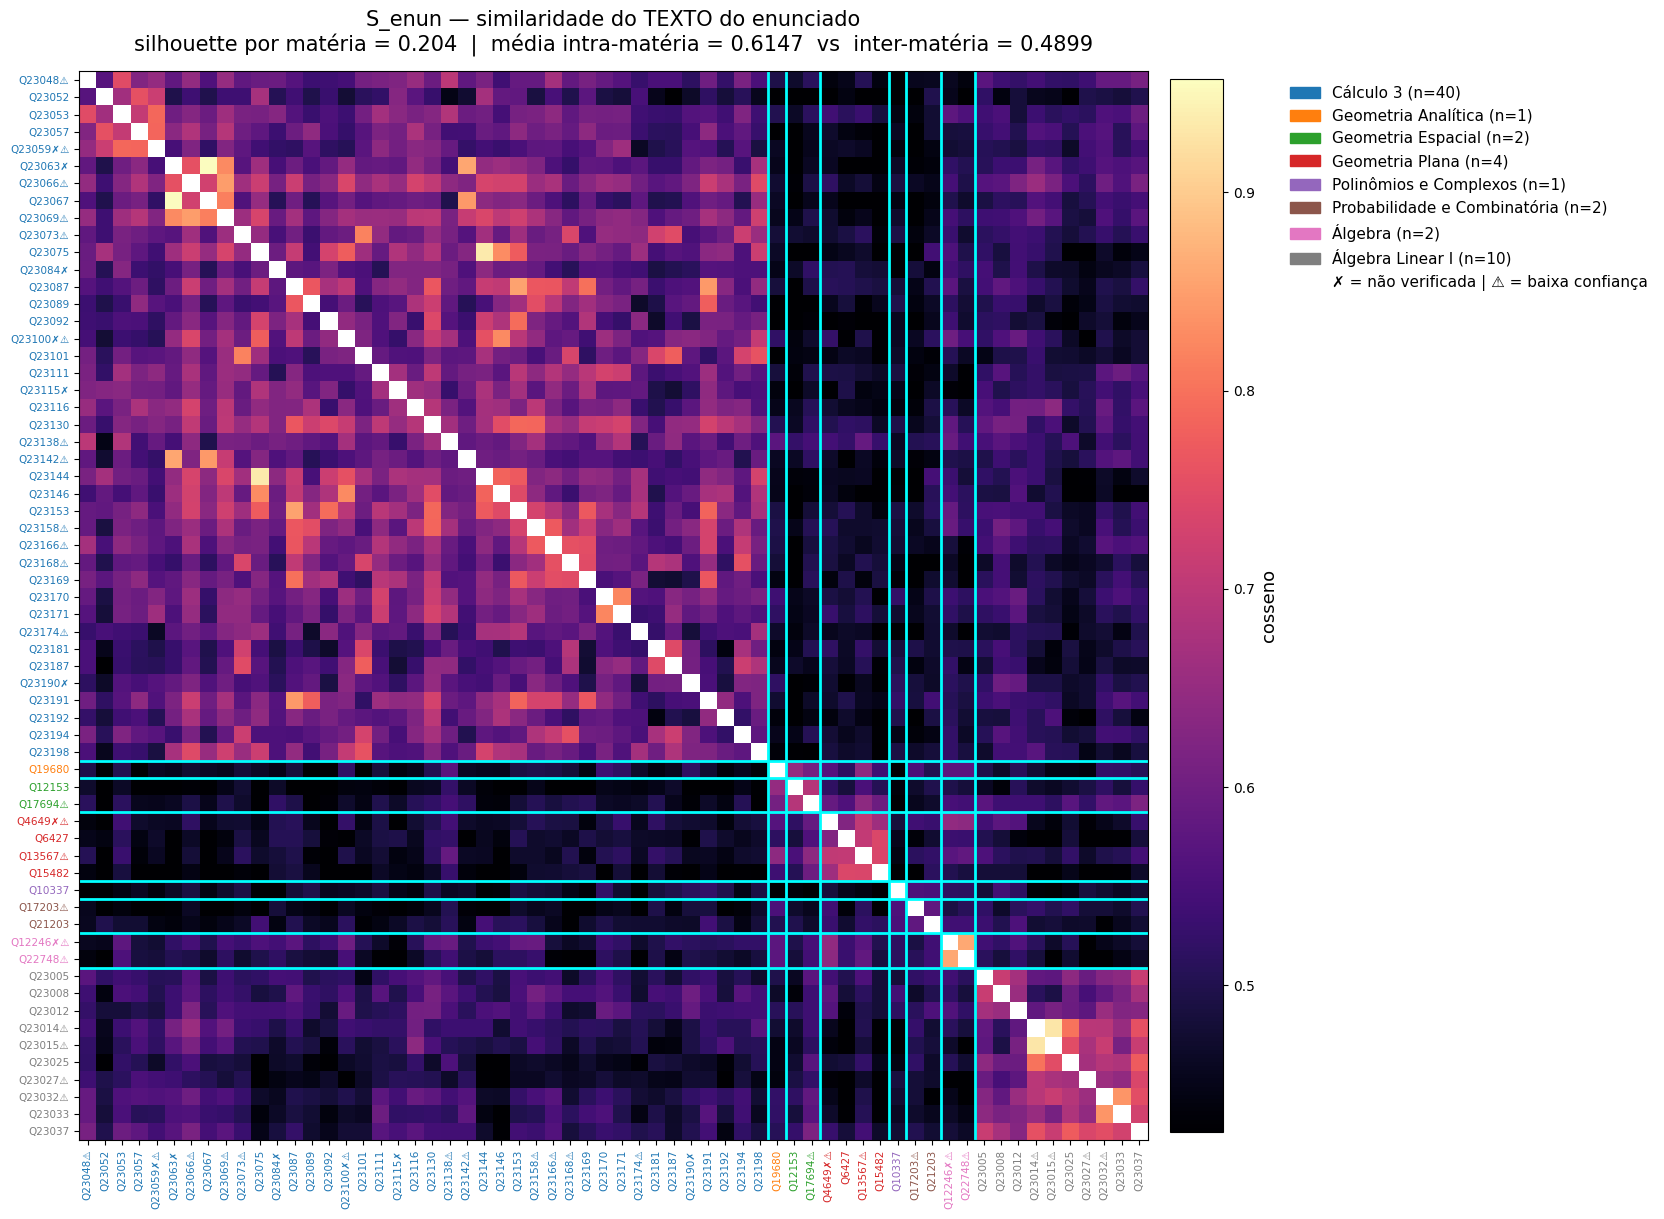

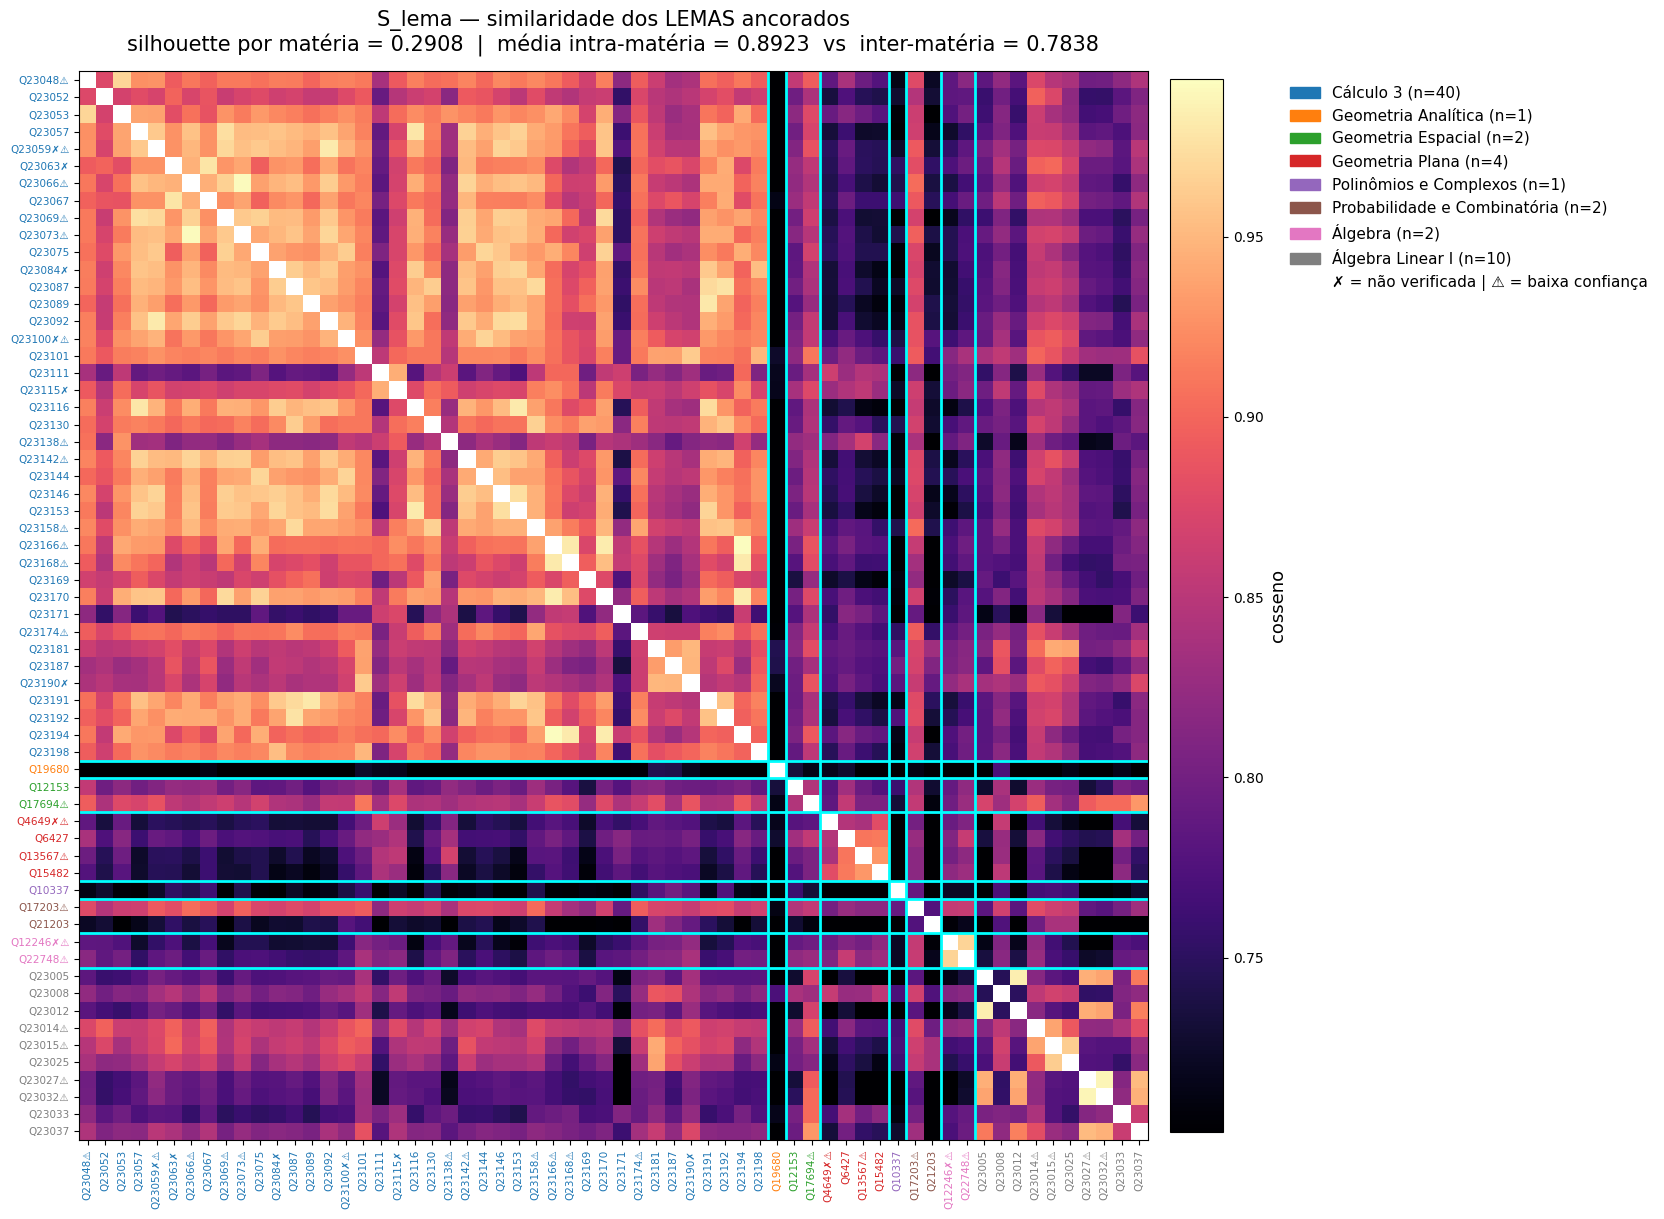

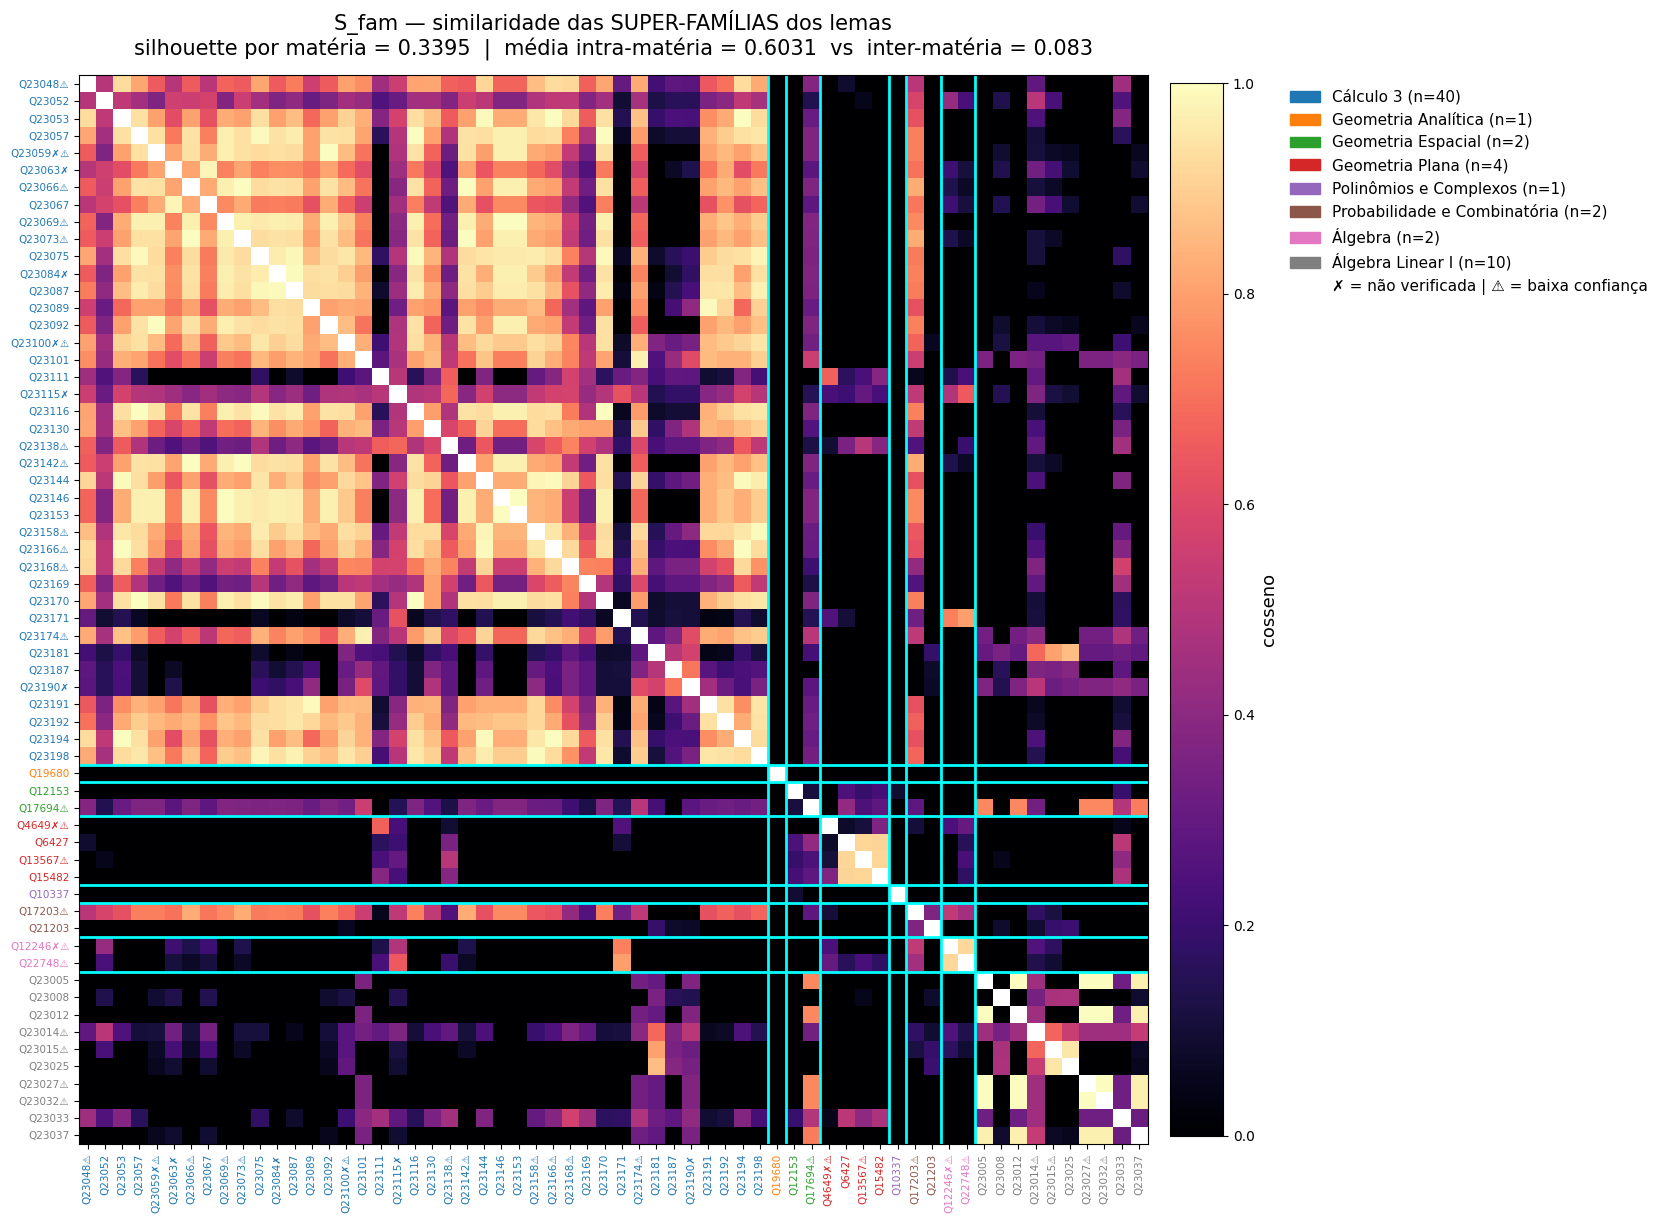

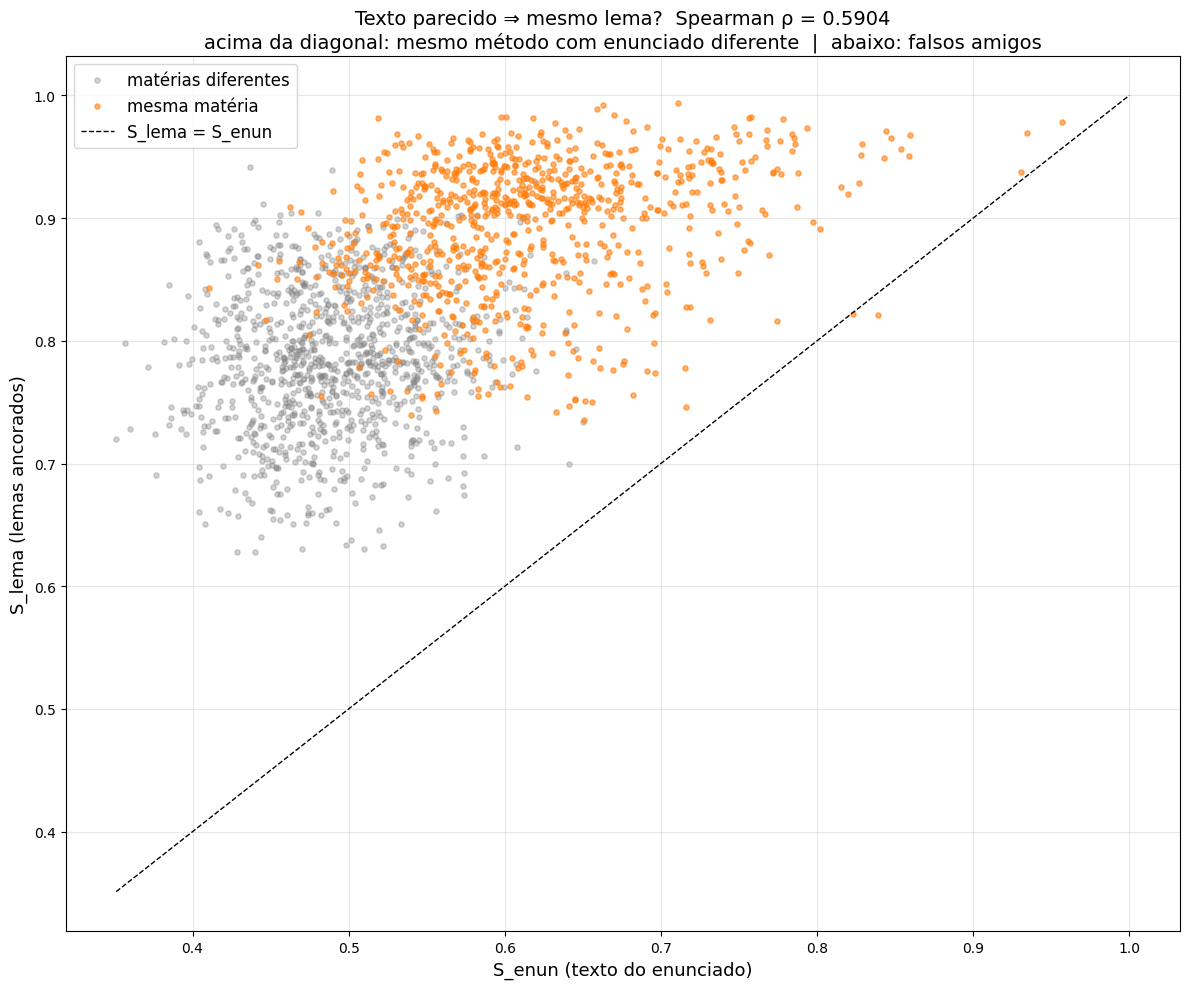

In [3]:
# 9.1. Heatmaps grandes da similaridade entre as 62 questões (lê os arquivos da Célula 9; não re-roda o encoder)
import json, shutil
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

drive_dir = Path("/content/drive/MyDrive/lemmas-pipeline")

# Runtime resetado apaga /content, mas o Drive guarda tudo: monta (se preciso) e traz de lá.
if not drive_dir.parent.exists():
    from google.colab import drive
    drive.mount("/content/drive")

def carregar(nome):
    local = Path(nome)
    if not local.exists():
        origem = drive_dir / nome
        if not origem.exists():
            raise FileNotFoundError(f"{nome} não está nem em /content nem no Drive — rode a Célula 9 primeiro.")
        shutil.copy(origem, local)
        print(f"[Drive -> /content] {nome}")
    return local

anc = json.load(open(carregar("ancoragem_vetorial_62.json"), encoding="utf-8"))
rel = json.load(open(carregar("ancoragem_62_relatorio.json"), encoding="utf-8"))
M = np.load(carregar("similaridade_questoes_62.npz"))

info = {r["id"]: r for r in anc}
ids = [int(i) for i in M["ids"]]
mat_of = lambda qid: info[qid].get("materia") or "?"
order = sorted(range(len(ids)), key=lambda i: (mat_of(ids[i]), ids[i]))
ids_ord = [ids[i] for i in order]
materias = sorted({mat_of(q) for q in ids})
cores = dict(zip(materias, plt.cm.tab10.colors))
tamanhos = [sum(1 for q in ids_ord if mat_of(q) == m) for m in materias]
bounds = np.cumsum(tamanhos)[:-1]

TITULOS = {
    "S_enun": "S_enun — similaridade do TEXTO do enunciado",
    "S_lema": "S_lema — similaridade dos LEMAS ancorados",
    "S_fam": "S_fam — similaridade das SUPER-FAMÍLIAS dos lemas",
}

def salvar(fig, nome):
    fig.savefig(nome, dpi=160, bbox_inches="tight")
    if drive_dir.parent.exists():
        shutil.copy(nome, drive_dir / nome)

for key in ("S_enun", "S_lema", "S_fam"):
    S = M[key][np.ix_(order, order)].copy()
    np.fill_diagonal(S, np.nan)  # diagonal = 1 sempre; esconder para não saturar a escala
    fig, ax = plt.subplots(figsize=(16, 14))
    vmin = np.nanpercentile(S, 5)
    im = ax.imshow(S, cmap="magma", vmin=vmin, vmax=np.nanmax(S), interpolation="nearest")
    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
    cb.set_label("cosseno", fontsize=13)

    labels = []
    for q in ids_ord:
        tag = "" if info[q]["verificada"] else "✗"
        tag += "⚠" if info[q]["baixa_confianca"] else ""
        labels.append(f"Q{q}{tag}")
    ax.set_xticks(range(len(ids_ord)))
    ax.set_yticks(range(len(ids_ord)))
    ax.set_xticklabels(labels, rotation=90, fontsize=7.5)
    ax.set_yticklabels(labels, fontsize=7.5)
    for tick, q in zip(ax.get_xticklabels(), ids_ord):
        tick.set_color(cores[mat_of(q)])
    for tick, q in zip(ax.get_yticklabels(), ids_ord):
        tick.set_color(cores[mat_of(q)])

    for b in bounds:
        ax.axhline(b - 0.5, color="cyan", lw=2)
        ax.axvline(b - 0.5, color="cyan", lw=2)

    st = rel["media_intra_inter"][key]
    ax.set_title(
        f"{TITULOS[key]}\n"
        f"silhouette por matéria = {rel['silhouette_por_materia'][key]}  |  "
        f"média intra-matéria = {st['intra_materia']}  vs  inter-matéria = {st['inter_materia']}",
        fontsize=15, pad=14,
    )
    ax.legend(
        handles=[Patch(color=cores[m], label=f"{m} (n={n})") for m, n in zip(materias, tamanhos)]
        + [Patch(color="white", label="✗ = não verificada | ⚠ = baixa confiança")],
        loc="upper left", bbox_to_anchor=(1.12, 1.0), fontsize=11, frameon=False,
    )
    plt.tight_layout()
    salvar(fig, f"ancoragem_62_heatmap_{key}.png")
    plt.show()

# Dispersão S_enun × S_lema (cada ponto = 1 par de questões)
iu = np.triu_indices(len(ids), 1)
same = np.array([[mat_of(a) == mat_of(b) for b in ids] for a in ids])[iu]
x, y = M["S_enun"][iu], M["S_lema"][iu]
fig, ax = plt.subplots(figsize=(12, 10))
ax.scatter(x[~same], y[~same], s=14, alpha=0.35, c="tab:gray", label="matérias diferentes")
ax.scatter(x[same], y[same], s=14, alpha=0.6, c="tab:orange", label="mesma matéria")
lims = [min(x.min(), y.min()), 1]
ax.plot(lims, lims, "k--", lw=1, label="S_lema = S_enun")
ax.set_xlabel("S_enun (texto do enunciado)", fontsize=13)
ax.set_ylabel("S_lema (lemas ancorados)", fontsize=13)
ax.set_title(
    f"Texto parecido ⇒ mesmo lema?  Spearman ρ = {rel['spearman']['enun_vs_lema']}\n"
    "acima da diagonal: mesmo método com enunciado diferente  |  abaixo: falsos amigos",
    fontsize=14,
)
ax.legend(fontsize=12)
ax.grid(alpha=0.3)
plt.tight_layout()
salvar(fig, "ancoragem_62_dispersao.png")
plt.show()


### 10. Etapa 2 — Juiz LLM de Ancoragem (Shortlist Top-25 + Super-Famílias $\to$ 0 a 5 Lemas) & Similaridade Híbrida 3D

**Por que o Passo Vetorial Puro (Célula 9) sofreu de falso-positivo por homonímia?**
Na Célula 9, o cosseno puro em cima de rótulos livres puxou homônimos falsos (ex.: `"triangularization"` de matrizes casou com *Números triangulares*; `"análise de paridade"` em Combinatória casou com *Função par* de Cálculo; `"Verificação de fechamento sob adição"` casou com *Equação Funcional de Cauchy*). Além disso, forçar sempre 5 lemas inflou a similaridade inter-matéria (`0.7838`).

**Como esta Etapa 2 resolve o problema (Alinhada às Seções 4 e 5 do Pacote Consolidado):**
1. **Shortlist Inteligente (`25` candidatos por questão):** Combina as **17 âncoras léxicas da Spec** (6 fechadas + 11 recomendadas), busca léxica em títulos, Top-15 vetorial (`BGE-M3 v2.1`) e irmãos das mesmas **Super-Famílias**.
2. **Juiz LLM (`Qwen/Qwen3-14B-AWQ`, greedy, checkpoint por questão no Drive):** Lê o enunciado + a solução passo a passo + os 25 candidatos e escolhe **entre `0` e `5` lemas que realmente foram aplicados na solução** (*"primo não é âncora"*). Se o lema exato não existir no catálogo 3k, ele registra o método em `novos_lemas_sugeridos` (mapeando lacunas do banco).
3. **Fórmula Oficial do Híbrido 3D (Seção 4 da Spec):**
$$S_{\text{híbrido}} = 0.65 \cdot S_{\text{lema (Jaccard ponderado 1.0 / 0.5)}} + 0.20 \cdot S_{\text{sem (BGE-M3)}} + 0.15 \cdot S_{\text{struct (LaTeX)}}$$


In [7]:
# 10. Etapa 2 — Juiz LLM (Qwen3-14B-AWQ) escolhendo 0 a 5 lemas da Shortlist + Similaridade Híbrida 3D (Spec)
# Script canônico sincronizado com: scripts/pipeline/etapa2_juiz_llm_ancoragem_62.py
from pathlib import Path
import json

drive_dir = Path("/content/drive/MyDrive/lemmas-pipeline")
if not drive_dir.parent.exists():
    from google.colab import drive
    drive.mount("/content/drive")

codigo_etapa2 = r'''"""Etapa 2 — Juiz LLM de Ancoragem (Shortlist Top-25 + Irmãos de Super-Família -> 0 a 5 Lemas) + Híbrido 3D (Spec).

Arquitetura em 2 Estágios (Retrieval + LLM Reranker/Judge) alinhada ao Pacote Consolidado:
1. Shortlist por Questão (~25 candidatos):
   - Combina os candidatos vetoriais (BGE-M3 v2.1: método + enunciado) com os irmãos das mesmas
     Super-Famílias e com as âncoras léxicas da Spec (6 fechadas + 11 recomendadas).
2. Juiz LLM (Qwen/Qwen3-14B-AWQ, greedy, enable_thinking=False):
   - Lê o enunciado + a solução já gerada + a shortlist numerada de ~25 candidatos do catálogo 3k.
   - Escolhe de 0 a 5 lemas que REALMENTE são usados na resolução (nunca força 5 se só 1 ou 2 servirem,
     e nunca usa "primo" como âncora).
   - Classifica o papel ("principal" ou "auxiliar"), cita o passo da solução e sinaliza
     `novos_lemas_sugeridos` quando um método da solução não tem lema correspondente no catálogo 3k.
   - Rejeita estritamente qualquer `lema_id` fora da shortlist (zero alucinação de ID).
   - Checkpoint incremental a cada questão no Google Drive (`ancoragem_llm_62_parcial.jsonl`).
3. Tabela `question_lemmas` + Similaridade Híbrida 3D da Spec:
   - S_lema   = Jaccard ponderado dos conjuntos de lemas/métodos (peso principal = 1.0, auxiliar = 0.5).
   - S_sem    = Cosseno BGE-M3 dos enunciados das 62 questões.
   - S_struct = Cosseno TF-IDF do esqueleto estrutural LaTeX (enunciado + solução).
   - S_hibrido = 0.65 * S_lema + 0.20 * S_sem + 0.15 * S_struct.
"""

import gc
import glob
import json
import re
import shutil
import unicodedata
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np

DRIVE_DIR = Path("/content/drive/MyDrive/lemmas-pipeline")
JUDGE_MODEL = "Qwen/Qwen3-14B-AWQ"
ENCODER_MODEL = "BAAI/bge-m3"
MAX_TOKENS_JUDGE = 1024

SHORTLIST_SIZE = 25
MAX_CHOSEN_LEMMAS = 5

# Pesos oficiais da Spec (Seção 4 do Pacote Consolidado)
W_HIB_LEMA = 0.65
W_HIB_SEM = 0.20
W_HIB_STRUCT = 0.15
W_JACCARD_PRINCIPAL = 1.0
W_JACCARD_AUXILIAR = 0.5

PARTIAL_LLM_PATH = "ancoragem_llm_62_parcial.jsonl"
OUT_ANCORAGEM_LLM = "ancoragem_llm_62.json"
OUT_QUESTION_LEMMAS = "question_lemmas_62.json"
OUT_HIBRIDO_NPZ = "similaridade_hibrida_62.npz"
OUT_HIBRIDO_JSON = "similaridade_hibrida_62_relatorio.json"

# Âncoras léxicas auditadas na Seção 5 do Pacote Consolidado (6 fechadas + 11 recomendadas)
LEXICAL_ANCHORS_SPEC = {
    # 6 Fechados (alta auditada)
    "volume-esfera": "LEMA-2337",
    "volume of a sphere": "LEMA-2337",
    "independencia-linear": "LEMA-2738",
    "linear independence": "LEMA-2738",
    "comprimento-de-curvas": "LEMA-1784",
    "comprimento de curvas": "LEMA-1784",
    "integração para comprimento de curva": "LEMA-1784",
    "multiplicadores-de-lagrange": "LEMA-1767",
    "multiplicadores de lagrange": "LEMA-1767",
    "metodo de multiplicadores de lagrange": "LEMA-1767",
    "metodo dos multiplicadores de lagrange": "LEMA-1767",
    "derivada-direcional": "LEMA-1796",
    "derivada direcional": "LEMA-1796",
    "teorema-funcao-implicita": "LEMA-1794",
    "teorema da funcao implicita": "LEMA-1794",
    # 11 Recomendações da Spec
    "casa-dos-pombos": "LEMA-0466",
    "principio da casa dos pombos": "LEMA-0466",
    "teorema-ceva": "LEMA-0022",
    "regra-da-cadeia": "LEMA-1793",
    "regra da cadeia": "LEMA-1793",
    "chain rule": "LEMA-1793",
    "regla de la cadena": "LEMA-1793",
    "equacao-plano-tangente": "LEMA-1792",
    "equacao do plano tangente": "LEMA-1792",
    "plano_tangente": "LEMA-1792",
    "plano-tangente-esfera": "LEMA-1792",
    "tangent plane to sphere": "LEMA-1792",
    "regra-do-produto": "LEMA-2762",
    "regra do produto": "LEMA-2762",
    "regla del producto": "LEMA-2762",
    "produto-escalar": "LEMA-2734",
    "produto escalar": "LEMA-2734",
    "produto_escalar": "LEMA-2734",
    "dot product formula": "LEMA-2734",
    "distancia-ponto-plano": "LEMA-2029",
    "distance from point to plane": "LEMA-2029",
    "derivadas-parciais-segunda-ordem": "LEMA-1791",
    "second-order partial derivatives": "LEMA-1791",
    "otimizacao-com-restricao": "LEMA-1767",
    "otimizacao com restricao": "LEMA-1767",
    "analise-hessiana": "LEMA-1799",
    "analise da hessiana": "LEMA-1799",
}

JUDGE_SYSTEM = (
    "Você é um especialista em Matemática e curador ontológico do projeto LemmaS. "
    "Sua tarefa é analisar o enunciado de uma questão, a resolução passo a passo já gerada "
    "e uma lista fechada (shortlist) de lemas candidatos do catálogo. "
    "Escolha APENAS os lemas da lista que são EFETIVAMENTE utilizados na resolução (entre 0 e 5 lemas). "
    "REGRA DE OURO: 'Primo não é âncora' — NÃO escolha um lema apenas porque é do mesmo assunto ou parecido; "
    "se o lema exato não estiver na lista de candidatos, NÃO force um lema vizinho e registre o método em 'novos_lemas_sugeridos'."
)


# ---------------------------------------------------------------- Utilitários I/O
def ensure_drive():
    if not DRIVE_DIR.parent.exists():
        try:
            from google.colab import drive
            drive.mount("/content/drive")
        except Exception:
            pass


def resolve(name):
    local = Path(name)
    if local.exists():
        return local
    if DRIVE_DIR.parent.exists() and (DRIVE_DIR / name).exists():
        shutil.copy(DRIVE_DIR / name, local)
        print(f"[Drive -> /content] {name}")
        return local
    return None


def load_json(name, required=True):
    path = resolve(name)
    if path is None:
        if required:
            raise FileNotFoundError(f"{name} não encontrado em ./ nem em {DRIVE_DIR}")
        return None
    return json.loads(path.read_text(encoding="utf-8"))


def sync_to_drive(path):
    if DRIVE_DIR.parent.exists():
        DRIVE_DIR.mkdir(parents=True, exist_ok=True)
        shutil.copy(path, DRIVE_DIR / Path(path).name)


def norm_slug(text):
    if not isinstance(text, str):
        return ""
    s = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode("ascii")
    s = re.sub(r"[^a-zA-Z0-9]+", " ", s.lower()).strip()
    return s


def load_partial(path):
    records = []
    p = resolve(path)
    if p and p.exists():
        for line in p.read_text(encoding="utf-8").splitlines():
            try:
                records.append(json.loads(line))
            except json.JSONDecodeError:
                continue
    return records


def append_partial(path, record):
    with open(path, "a", encoding="utf-8") as f:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")
    sync_to_drive(path)


def as_list(val):
    if val is None:
        return []
    if isinstance(val, str):
        return [val] if val.strip() else []
    return [v for v in val if isinstance(v, str) and v.strip()]


# ------------------------------------------------ Carregamento das 62 Questões e Soluções
def load_questoes_e_solucoes():
    """Reúne enunciados, soluções completas e rótulos (incluindo questoes_62.json / metodos_62_norm.json se presentes)."""
    info = defaultdict(dict)
    names = {
        Path(p).name
        for p in glob.glob("questoes*.json") + glob.glob(str(DRIVE_DIR / "questoes*.json"))
    }
    names |= {"questoes_62.json", "solucoes_dois_modelos.json", "solucoes_lote1.json", "solucoes_lote1_corrigido.json"}
    for name in sorted(names):
        data = load_json(name, required=False)
        if isinstance(data, dict):
            data = next((v for v in data.values() if isinstance(v, list)), None)
        if not isinstance(data, list):
            continue
        for r in data:
            if not isinstance(r, dict) or "id" not in r:
                continue
            slot = info[r["id"]]
            for k in ("enunciado", "materia", "topico", "solucao_modelo_a", "solucao"):
                if r.get(k) and not slot.get(k):
                    slot[k] = r[k]

    piloto = load_json("metodos_amostra_v2.json")
    lote1 = load_json("metodos_lote1.json")
    rev = {r["id"]: r for r in (load_json("reverificacao_8.json", required=False) or [])}
    norm62_raw = load_json("metodos_62_norm.json", required=False)
    norm62 = {}
    if isinstance(norm62_raw, list):
        norm62 = {r["id"]: r for r in norm62_raw if isinstance(r, dict) and "id" in r}
    elif isinstance(norm62_raw, dict):
        norm62 = {int(k): v for k, v in norm62_raw.items() if str(k).isdigit()}

    def build_items(records, lote):
        out = []
        for r in records:
            qid = r["id"]
            principal = as_list(r.get("principal") or r.get("principal_final"))
            auxiliares = as_list(r.get("auxiliares"))
            if not auxiliares and r.get("metodos_finais"):
                auxiliares = [m for m in as_list(r["metodos_finais"]) if m not in principal]
            verificada = r.get("verificada", r.get("correta"))
            fonte = "solver+verificador_7b"
            if qid in rev:
                rv = rev[qid]
                principal = as_list(rv.get("principal_final_32b")) or principal
                auxiliares = [m for m in as_list(rv.get("metodos_finais_32b")) if m not in principal]
                verificada = rv.get("correta_32b") is True
                fonte = "reverificacao_32b"
            if qid in norm62:
                n_rec = norm62[qid]
                p_norm = as_list(n_rec.get("principal"))
                a_norm = as_list(n_rec.get("auxiliares"))
            else:
                p_norm, a_norm = [], []
            meta = info.get(qid, {})
            out.append(
                {
                    "id": qid,
                    "lote": lote,
                    "materia": meta.get("materia"),
                    "topico": meta.get("topico"),
                    "enunciado": meta.get("enunciado") or "",
                    "solucao": meta.get("solucao_modelo_a") or meta.get("solucao") or "",
                    "principal": principal,
                    "auxiliares": auxiliares,
                    "principal_norm": p_norm,
                    "auxiliares_norm": a_norm,
                    "verificada": bool(verificada),
                    "fonte_rotulo": fonte,
                }
            )
        return out

    questoes = build_items(piloto, "piloto") + build_items(lote1, "lote1")
    print(f"[Questões] Carregadas {len(questoes)} questões (12 piloto + 50 lote 1).")
    return questoes


# ------------------------------------------------ Shortlist (Vetorial + Léxico + Super-Família)
def build_shortlists(questoes, catalog, vectors, families):
    by_id = {l["id"]: l for l in catalog}
    by_code = {l.get("codigo"): l for l in catalog if l.get("codigo")}
    fam_by_id = {f["id"]: f for f in families}
    members_by_fam = defaultdict(list)
    for f in families:
        members_by_fam[f["super_family_id"]].append(f["id"])

    lemma_ids = [v["id"] for v in vectors]
    idx_by_id = {lid: i for i, lid in enumerate(lemma_ids)}
    L = np.asarray([v["vetor"] for v in vectors], dtype=np.float32)
    L /= np.linalg.norm(L, axis=1, keepdims=True) + 1e-12

    import torch
    from sentence_transformers import SentenceTransformer

    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"[Shortlist BGE-M3] Codificando consultas em {device}...")
    encoder = SentenceTransformer(ENCODER_MODEL, device=device)

    enun_texts = [
        f"Matéria: {q.get('materia') or ''}. Tópico: {q.get('topico') or ''}. "
        f"Enunciado: {q.get('enunciado') or q.get('solucao')[:600]}"
        for q in questoes
    ]
    E_q = np.asarray(encoder.encode(enun_texts, batch_size=64, normalize_embeddings=True), dtype=np.float32)

    all_labels = sorted(
        {
            lab
            for q in questoes
            for lab in (q["principal"] + q["auxiliares"] + q["principal_norm"] + q["auxiliares_norm"])
        }
    )
    E_lab = {}
    if all_labels:
        lab_vecs = np.asarray(
            encoder.encode(
                ["Título: " + l.replace("-", " ").replace("_", " ").strip() for l in all_labels],
                batch_size=64,
                normalize_embeddings=True,
            ),
            dtype=np.float32,
        )
        E_lab = dict(zip(all_labels, lab_vecs))

    del encoder
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    S_enun_lema = E_q @ L.T
    shortlists = {}

    for qi, q in enumerate(questoes):
        sim_enun = S_enun_lema[qi]
        labels_q = q["principal"] + q["auxiliares"] + q["principal_norm"] + q["auxiliares_norm"]
        if labels_q:
            per_lab = np.stack([E_lab[lab] @ L.T for lab in labels_q])
            sim_met = per_lab.max(axis=0)
            score = 0.65 * sim_met + 0.35 * sim_enun
        else:
            sim_met = np.zeros_like(sim_enun)
            score = sim_enun.copy()

        chosen_ids = []
        chosen_reason = {}

        # 1. Âncoras Léxicas da Spec (prioridade máxima se o rótulo bater)
        for lab in labels_q:
            slug_k = norm_slug(lab)
            slug_hyph = slug_k.replace(" ", "-")
            for key_cand in (lab.lower().strip(), slug_k, slug_hyph):
                if key_cand in LEXICAL_ANCHORS_SPEC:
                    code = LEXICAL_ANCHORS_SPEC[key_cand]
                    if code in by_code:
                        lid = by_code[code]["id"]
                        if lid not in chosen_ids:
                            chosen_ids.append(lid)
                            chosen_reason[lid] = f"ancora_lexica_spec({code})"

        # 2. Casamento Léxico Direto no Título do Catálogo 3k (Tier 1/2)
        for lab in labels_q:
            words = [w for w in norm_slug(lab).split() if len(w) >= 4]
            if not words:
                continue
            for l in catalog:
                tit_norm = norm_slug(l.get("titulo") or "")
                if all(w in tit_norm for w in words):
                    lid = l["id"]
                    if lid not in chosen_ids:
                        chosen_ids.append(lid)
                        chosen_reason[lid] = f"lexico_titulo('{lab}')"
                    if len(chosen_ids) >= 8:
                        break

        # 3. Top-15 pelo Score Combinado (0.65 * método + 0.35 * enunciado)
        for j in np.argsort(-score)[:15]:
            lid = lemma_ids[int(j)]
            if lid not in chosen_ids:
                chosen_ids.append(lid)
                chosen_reason[lid] = "top_score_vetorial"

        # 4. Top-5 pelo Enunciado Puro (garante cobertura quando rótulo é fraco ou vazio)
        for j in np.argsort(-sim_enun)[:5]:
            lid = lemma_ids[int(j)]
            if lid not in chosen_ids:
                chosen_ids.append(lid)
                chosen_reason[lid] = "top_enunciado"

        # 5. Expansão por Super-Família (irmãos mais fortes das famílias dos top-3)
        top_fams = []
        for lid in chosen_ids[:4]:
            fid = fam_by_id.get(lid, {}).get("super_family_id")
            if fid is not None and fid not in top_fams:
                top_fams.append(fid)
        for fid in top_fams:
            siblings = sorted(
                members_by_fam[fid],
                key=lambda s_id: -float(score[idx_by_id[s_id]]),
            )
            for s_id in siblings[:3]:
                if s_id not in chosen_ids:
                    chosen_ids.append(s_id)
                    chosen_reason[s_id] = f"irmao_super_familia_{fid}"

        # Trunca em SHORTLIST_SIZE ordenando por prioridade léxica + score vetorial
        final_ids = chosen_ids[:SHORTLIST_SIZE]
        cand_list = []
        for rank, lid in enumerate(final_ids, 1):
            j = idx_by_id[lid]
            lem = by_id[lid]
            fam = fam_by_id.get(lid, {})
            cand_list.append(
                {
                    "rank_shortlist": rank,
                    "lema_id": lid,
                    "codigo": lem.get("codigo"),
                    "titulo": lem.get("titulo"),
                    "materia": lem.get("materia"),
                    "origem": lem.get("origem"),
                    "gatilho": (lem.get("gatilho_reconhecimento") or "")[:140],
                    "formula_latex": (lem.get("formula_latex") or "")[:120],
                    "super_family_id": fam.get("super_family_id"),
                    "score_vetorial": round(float(score[j]), 4),
                    "sim_metodo": round(float(sim_met[j]), 4),
                    "sim_enunciado": round(float(sim_enun[j]), 4),
                    "fonte_shortlist": chosen_reason.get(lid, "vetorial"),
                }
            )
        shortlists[q["id"]] = cand_list

    return shortlists, E_q, L, idx_by_id


# ------------------------------------------------ Juiz LLM (Qwen3-14B-AWQ)
def extract_json_block(text):
    if not text:
        return None
    blocks = re.findall(r"```json\s*(\{.*?\})\s*```", text, re.DOTALL)
    if not blocks and "{" in text and "}" in text:
        blocks = [text[text.find("{"):text.rfind("}") + 1]]
    for cand in reversed(blocks):
        try:
            parsed = json.loads(cand)
            if isinstance(parsed, dict):
                return parsed
        except Exception:
            continue
    return None


def build_judge_prompt(q, candidates):
    rotulos_livres = q["principal"] + q["auxiliares"]
    cand_lines = []
    for c in candidates:
        form = f" | Fórmula: {c['formula_latex']}" if c.get("formula_latex") else ""
        gat = f" | Uso: {c['gatilho']}" if c.get("gatilho") else ""
        cand_lines.append(
            f"- ID {c['lema_id']} ({c['codigo']}) [{c['materia']} | fam #{c['super_family_id']}]: "
            f"{c['titulo']}{form}{gat}"
        )
    cand_block = "\n".join(cand_lines)
    sol_excerpt = (q.get("solucao") or "")[:2200]
    enun_excerpt = (q.get("enunciado") or "")[:900]

    return (
        f"QUESTÃO (ID {q['id']} | Matéria: {q.get('materia')} | Tópico: {q.get('topico')}):\n"
        f"{enun_excerpt}\n\n"
        f"RESOLUÇÃO PASSO A PASSO:\n{sol_excerpt}\n\n"
        f"MÉTODOS IDENTIFICADOS PELO SOLVER/VERIFICADOR: {rotulos_livres}\n\n"
        f"SHORTLIST DE LEMAS CANDIDATOS DO CATÁLOGO (escolha APENAS desta lista, pelos IDs exatos):\n"
        f"{cand_block}\n\n"
        "INSTRUÇÕES ESTRITAS:\n"
        "1. Escolha entre 0 e 5 lemas da SHORTLIST acima que são REALMENTE usados na resolução.\n"
        "2. NÃO escolha lemas 'primos' (parecidos mas que não foram aplicados na solução). Se um método usado na solução não tiver lema exato na shortlist, NÃO force um substituto: coloque o nome do método em 'novos_lemas_sugeridos'.\n"
        "3. Para cada lema escolhido, indique 'papel' ('principal' ou 'auxiliar') e cite brevemente em qual passo da resolução ele entra.\n"
        "4. Responda APENAS com um bloco JSON válido no formato exato abaixo:\n"
        "```json\n"
        "{\n"
        '  "lemas_escolhidos": [\n'
        '    {"lema_id": 1234, "codigo": "LEMA-XXXX", "papel": "principal", "evidencia_na_solucao": "Usado para..."}\n'
        "  ],\n"
        '  "novos_lemas_sugeridos": ["nome-do-lema-faltante-se-houver"],\n'
        '  "procedimentos_gerais": ["substituicao-de-variaveis"]\n'
        "}\n"
        "```"
    )


def run_llm_judge(questoes, shortlists, catalog):
    by_id = {l["id"]: l for l in catalog}
    cached = load_partial(PARTIAL_LLM_PATH)
    done_by_id = {r["id"]: r for r in cached if "id" in r}
    pending = [q for q in questoes if q["id"] not in done_by_id]

    if not pending:
        print(f"[Cache Juiz LLM] 62/62 questões já julgadas em {PARTIAL_LLM_PATH}.")
        return [done_by_id[q["id"]] for q in questoes]

    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer

    print(f"[Juiz LLM] Carregando {JUDGE_MODEL} para julgar {len(pending)} questões pendentes...")
    tokenizer = AutoTokenizer.from_pretrained(JUDGE_MODEL)
    model = AutoModelForCausalLM.from_pretrained(
        JUDGE_MODEL, torch_dtype=torch.float16, device_map="auto"
    )

    try:
        for idx, q in enumerate(pending, 1):
            qid = q["id"]
            cands = shortlists[qid]
            valid_ids = {c["lema_id"]: c for c in cands}
            user_prompt = build_judge_prompt(q, cands)

            messages = [
                {"role": "system", "content": JUDGE_SYSTEM},
                {"role": "user", "content": user_prompt},
            ]
            text = tokenizer.apply_chat_template(
                messages, tokenize=False, add_generation_prompt=True, enable_thinking=False
            )
            inputs = tokenizer(text, return_tensors="pt").to(model.device)
            outputs = model.generate(**inputs, max_new_tokens=MAX_TOKENS_JUDGE, do_sample=False)
            raw_reply = tokenizer.decode(
                outputs[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True
            )
            parsed = extract_json_block(raw_reply) or {}

            chosen_clean = []
            seen_lids = set()
            rejected_ids = []
            for item in (parsed.get("lemas_escolhidos") or []):
                if not isinstance(item, dict):
                    continue
                lid = item.get("lema_id")
                try:
                    lid = int(lid)
                except (TypeError, ValueError):
                    continue
                if lid not in valid_ids:
                    rejected_ids.append(lid)
                    continue
                if lid in seen_lids:
                    continue
                seen_lids.add(lid)
                lem = by_id[lid]
                cand_meta = valid_ids[lid]
                papel = str(item.get("papel") or "auxiliar").lower().strip()
                if papel not in ("principal", "auxiliar"):
                    papel = "principal" if not chosen_clean else "auxiliar"
                chosen_clean.append(
                    {
                        "lema_id": lid,
                        "codigo": lem.get("codigo"),
                        "titulo": lem.get("titulo"),
                        "materia_lema": lem.get("materia"),
                        "origem": lem.get("origem"),
                        "papel": papel,
                        "evidencia_na_solucao": (item.get("evidencia_na_solucao") or "")[:240],
                        "super_family_id": cand_meta.get("super_family_id"),
                        "score_vetorial": cand_meta.get("score_vetorial"),
                        "fonte_shortlist": cand_meta.get("fonte_shortlist"),
                    }
                )
                if len(chosen_clean) >= MAX_CHOSEN_LEMMAS:
                    break

            # Garante pelo menos 1 principal se escolheu algum lema e todos vieram como auxiliar
            if chosen_clean and not any(c["papel"] == "principal" for c in chosen_clean):
                chosen_clean[0]["papel"] = "principal"

            record = {
                "id": qid,
                "lote": q["lote"],
                "materia": q.get("materia"),
                "topico": q.get("topico"),
                "verificada": q["verificada"],
                "fonte_rotulo": q["fonte_rotulo"],
                "rotulos_originais": {"principal": q["principal"], "auxiliares": q["auxiliares"]},
                "tipo": "AI_INTERPRETATION",
                "status": "ancorado_llm_shortlist",
                "modelo_juiz": JUDGE_MODEL,
                "n_candidatos_shortlist": len(cands),
                "n_lemas_escolhidos": len(chosen_clean),
                "lemas_escolhidos": chosen_clean,
                "novos_lemas_sugeridos": as_list(parsed.get("novos_lemas_sugeridos")),
                "procedimentos_gerais": as_list(parsed.get("procedimentos_gerais")),
                "ids_rejeitados_fora_shortlist": rejected_ids,
                "shortlist_top10_preview": [
                    {
                        "lema_id": c["lema_id"],
                        "codigo": c["codigo"],
                        "titulo": c["titulo"],
                        "score_vetorial": c["score_vetorial"],
                        "fonte": c["fonte_shortlist"],
                    }
                    for c in cands[:10]
                ],
                "resposta_bruta_llm": raw_reply,
            }
            done_by_id[qid] = record
            append_partial(PARTIAL_LLM_PATH, record)
            print(
                f"[{ len(done_by_id) }/62] Q{qid} ({q.get('materia')}): "
                f"{len(chosen_clean)} lemas escolhidos | novos={record['novos_lemas_sugeridos']}"
            )
    finally:
        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    return [done_by_id[q["id"]] for q in questoes]


# ------------------------------------------------ Similaridade Híbrida 3D (Spec Seção 4)
def normalize_latex_skeleton(text):
    if not isinstance(text, str) or not text.strip():
        return ""
    tokens = re.findall(r"\\[a-zA-Z]+|\d+|[\+\-\=\<\>\^\{\}\(\)\[\]\|]", text)
    return " ".join(tokens)


def build_question_keys(record, q_raw):
    """Monta o dicionário {chave: peso} de cada questão (peso 1.0 principal, 0.5 auxiliar).

    Combina:
    - Códigos LEMA-xxxx escolhidos pelo Juiz LLM;
    - Slugs normalizados / procedimentos para que métodos sem candidato no banco (como
      'substituicao-variaveis' ou 'verificacao-fechamento-adicao') continuem pontuando no híbrido,
      exatamente como especificado na Seção 5 do Pacote Consolidado.
    """
    weights = {}
    for c in record["lemas_escolhidos"]:
        key = c.get("codigo") or f"LEMA_ID_{c['lema_id']}"
        w = W_JACCARD_PRINCIPAL if c.get("papel") == "principal" else W_JACCARD_AUXILIAR
        weights[key] = max(weights.get(key, 0.0), w)

    # Inclui também slugs de métodos/procedimentos quando a questão usa procedimento sem lema fechado
    p_list = q_raw.get("principal_norm") or q_raw.get("principal") or []
    a_list = q_raw.get("auxiliares_norm") or q_raw.get("auxiliares") or []
    for m in p_list:
        slug = norm_slug(m).replace(" ", "-")
        if not slug:
            continue
        code = LEXICAL_ANCHORS_SPEC.get(slug) or LEXICAL_ANCHORS_SPEC.get(norm_slug(m))
        key = code if code else f"slug:{slug}"
        weights[key] = max(weights.get(key, 0.0), W_JACCARD_PRINCIPAL)
    for m in a_list:
        slug = norm_slug(m).replace(" ", "-")
        if not slug:
            continue
        code = LEXICAL_ANCHORS_SPEC.get(slug) or LEXICAL_ANCHORS_SPEC.get(norm_slug(m))
        key = code if code else f"slug:{slug}"
        weights[key] = max(weights.get(key, 0.0), W_JACCARD_AUXILIAR)

    return weights


def weighted_jaccard_matrix(weight_dicts):
    n = len(weight_dicts)
    S = np.zeros((n, n), dtype=np.float32)
    for i in range(n):
        wi = weight_dicts[i]
        for j in range(i, n):
            if i == j:
                S[i, j] = 1.0
                continue
            wj = weight_dicts[j]
            if not wi or not wj:
                S[i, j] = 0.0
                continue
            keys = set(wi.keys()) | set(wj.keys())
            inter = sum(min(wi.get(k, 0.0), wj.get(k, 0.0)) for k in keys)
            union = sum(max(wi.get(k, 0.0), wj.get(k, 0.0)) for k in keys)
            val = float(inter / union) if union > 0 else 0.0
            S[i, j] = S[j, i] = val
    return S


def compute_hybrid_3d(questoes, llm_records, E_q, L, idx_by_id):
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.preprocessing import normalize

    n = len(questoes)
    # 1. S_sem (Cosseno BGE-M3 dos enunciados)
    S_sem = (E_q @ E_q.T).astype(np.float32)

    # 2. S_struct (Cosseno TF-IDF do esqueleto LaTeX de enunciado + solução)
    skeletons = [
        normalize_latex_skeleton((q.get("enunciado") or "") + " " + (q.get("solucao") or ""))
        for q in questoes
    ]
    non_empty = [s for s in skeletons if s.strip()]
    if non_empty:
        vec = TfidfVectorizer(token_pattern=r"[^\s]+", ngram_range=(1, 2), sublinear_tf=True)
        vec.fit(non_empty)
        X_struct = np.zeros((n, len(vec.vocabulary_)), dtype=np.float32)
        for i, sk in enumerate(skeletons):
            if sk.strip():
                X_struct[i] = vec.transform([sk]).toarray()[0]
        X_struct = normalize(X_struct, norm="l2")
        S_struct = (X_struct @ X_struct.T).astype(np.float32)
        for i in range(n):
            S_struct[i, i] = 1.0
    else:
        S_struct = np.eye(n, dtype=np.float32)

    # 3. S_lema_jaccard (Jaccard Ponderado exato da Spec: principal=1.0, auxiliar=0.5)
    weight_dicts = [
        build_question_keys(rec, q) for rec, q in zip(llm_records, questoes)
    ]
    S_lema_jaccard = weighted_jaccard_matrix(weight_dicts)

    # 4. S_lema_vetorial (Cosseno entre os centróides BGE-M3 dos lemas escolhidos pelo Juiz LLM)
    perfis_vec = np.zeros((n, L.shape[1]), dtype=np.float32)
    for i, rec in enumerate(llm_records):
        for c in rec["lemas_escolhidos"]:
            w = W_JACCARD_PRINCIPAL if c["papel"] == "principal" else W_JACCARD_AUXILIAR
            perfis_vec[i] += w * L[idx_by_id[c["lema_id"]]]
        if np.linalg.norm(perfis_vec[i]) < 1e-9:
            perfis_vec[i] = E_q[i]
    perfis_vec /= np.linalg.norm(perfis_vec, axis=1, keepdims=True) + 1e-12
    S_lema_vetorial = (perfis_vec @ perfis_vec.T).astype(np.float32)

    # 5. S_hibrido oficial da Spec: 0.65 * S_lema + 0.20 * S_sem + 0.15 * S_struct
    S_hibrido = (
        W_HIB_LEMA * S_lema_jaccard
        + W_HIB_SEM * S_sem
        + W_HIB_STRUCT * S_struct
    ).astype(np.float32)

    return S_lema_jaccard, S_lema_vetorial, S_sem, S_struct, S_hibrido, weight_dicts


def build_question_lemmas_table(llm_records):
    """Gera a tabela relacional question_lemmas pronta para auditoria (não importa no Supabase)."""
    rows = []
    for r in llm_records:
        for rank, c in enumerate(r["lemas_escolhidos"], 1):
            rows.append(
                {
                    "question_id": r["id"],
                    "lote": r["lote"],
                    "lema_id": c["lema_id"],
                    "codigo": c["codigo"],
                    "titulo": c["titulo"],
                    "papel": c["papel"],
                    "peso_jaccard": W_JACCARD_PRINCIPAL if c["papel"] == "principal" else W_JACCARD_AUXILIAR,
                    "rank": rank,
                    "evidencia_na_solucao": c["evidencia_na_solucao"],
                    "super_family_id": c["super_family_id"],
                    "tipo": "AI_INTERPRETATION",
                }
            )
    return rows


def ensure_awq_deps_before_torch():
    """Garante que gptqmodel seja instalado ANTES de importar torch/triton no processo."""
    import importlib.util
    import subprocess
    import sys

    if importlib.util.find_spec("gptqmodel") is None:
        print("[Auto-Deps] Instalando gptqmodel + torchvision==0.29.2 torchaudio==2.11.1 (processo limpo)...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gptqmodel"], check=True)
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", "torchvision==0.29.2", "torchaudio==2.11.1"],
            check=True,
        )


def main():
    ensure_awq_deps_before_torch()
    ensure_drive()
    questoes = load_questoes_e_solucoes()
    catalog = load_json("lemas_3k.json")
    vectors = load_json("lemas_vetores_3k.json")
    families = load_json("lemas_super_familias_3k.json")

    shortlists, E_q, L, idx_by_id = build_shortlists(questoes, catalog, vectors, families)
    llm_records = run_llm_judge(questoes, shortlists, catalog)
    q_lemmas = build_question_lemmas_table(llm_records)

    S_jac, S_vec, S_sem, S_struct, S_hib, weight_dicts = compute_hybrid_3d(
        questoes, llm_records, E_q, L, idx_by_id
    )

    ids = [q["id"] for q in questoes]
    iu = np.triu_indices(len(ids), 1)

    # Pares de destaque no Híbrido 3D
    def top_pairs(mat, k=12):
        vals = mat[iu]
        order = np.argsort(-vals)[:k]
        out = []
        for o in order:
            i, j = int(iu[0][o]), int(iu[1][o])
            ki = set(weight_dicts[i].keys()) & set(weight_dicts[j].keys())
            out.append(
                {
                    "q_a": ids[i],
                    "q_b": ids[j],
                    "materia_a": questoes[i].get("materia"),
                    "materia_b": questoes[j].get("materia"),
                    "S_hibrido": round(float(S_hib[i, j]), 4),
                    "S_lema_jaccard": round(float(S_jac[i, j]), 4),
                    "S_lema_vetorial": round(float(S_vec[i, j]), 4),
                    "S_sem": round(float(S_sem[i, j]), 4),
                    "S_struct": round(float(S_struct[i, j]), 4),
                    "chaves_em_comum": sorted(ki),
                }
            )
        return out

    novos_counter = Counter(
         norm_slug(nl).replace(" ", "-")
        for r in llm_records
        for nl in r.get("novos_lemas_sugeridos", [])
        if norm_slug(nl)
    )
    cobertura_shortlist = sum(1 for r in llm_records if r["n_lemas_escolhidos"] > 0)

    relatorio = {
        "n_questoes": len(questoes),
        "cobertura_shortlist_questoes_com_lema": f"{cobertura_shortlist}/{len(questoes)} ({cobertura_shortlist/len(questoes):.1%})",
        "media_lemas_por_questao": round(float(np.mean([r["n_lemas_escolhidos"] for r in llm_records])), 2),
        "distribuicao_n_lemas_escolhidos": dict(Counter(r["n_lemas_escolhidos"] for r in llm_records)),
        "total_vinculos_question_lemmas": len(q_lemmas),
        "total_alucinacoes_id_rejeitadas": sum(len(r["ids_rejeitados_fora_shortlist"]) for r in llm_records),
        "pares_com_S_lema_jaccard_positivo": int((S_jac[iu] > 0).sum()),
        "total_pares": int(len(iu[0])),
        "pesos_hibrido_spec": {"S_lema": W_HIB_LEMA, "S_sem": W_HIB_SEM, "S_struct": W_HIB_STRUCT},
        "top_novos_lemas_sugeridos_lacunas_catalogo": [
            {"sugestao": k, "n_questoes": c} for k, c in novos_counter.most_common(15)
        ],
        "top_pares_hibrido_3d": top_pairs(S_hib, 15),
        "top_pares_jaccard_lema": top_pairs(S_jac, 15),
    }

    Path(OUT_ANCORAGEM_LLM).write_text(json.dumps(llm_records, ensure_ascii=False, indent=2), encoding="utf-8")
    Path(OUT_QUESTION_LEMMAS).write_text(json.dumps(q_lemmas, ensure_ascii=False, indent=2), encoding="utf-8")
    Path(OUT_HIBRIDO_JSON).write_text(json.dumps(relatorio, ensure_ascii=False, indent=2), encoding="utf-8")
    np.savez_compressed(
        OUT_HIBRIDO_NPZ,
        ids=np.array(ids),
        S_hibrido=S_hib,
        S_lema_jaccard=S_jac,
        S_lema_vetorial=S_vec,
        S_sem=S_sem,
        S_struct=S_struct,
    )
    for p in (OUT_ANCORAGEM_LLM, OUT_QUESTION_LEMMAS, OUT_HIBRIDO_JSON, OUT_HIBRIDO_NPZ):
        sync_to_drive(p)

    print(
        f"[OK] {OUT_ANCORAGEM_LLM}, {OUT_QUESTION_LEMMAS}, {OUT_HIBRIDO_NPZ} e {OUT_HIBRIDO_JSON} "
        "gravados em /content e sincronizados no Google Drive!"
    )


if __name__ == "__main__":
    main()
'''
Path("/content/etapa2_juiz_llm_ancoragem_62.py").write_text(codigo_etapa2, encoding="utf-8")

# Usa !python3 -u (igual às Células 6 e 8) em processo limpo com torch/triton já atualizados
!python3 -u /content/etapa2_juiz_llm_ancoragem_62.py

if not Path("ancoragem_llm_62.json").exists():
    raise RuntimeError("etapa2_juiz_llm_ancoragem_62.py parou antes de gerar ancoragem_llm_62.json. Veja o log impresso acima!")

anc_llm = json.load(open("ancoragem_llm_62.json", encoding="utf-8"))
rel_hib = json.load(open("similaridade_hibrida_62_relatorio.json", encoding="utf-8"))

print("\n" + "=" * 100)
print("RESUMO DO JUIZ LLM (0 a 5 LEMAS POR QUESTÃO) + HÍBRIDO 3D DA SPEC")
print("=" * 100)
print(json.dumps({
    k: rel_hib[k] for k in (
        "n_questoes",
        "cobertura_shortlist_questoes_com_lema",
        "media_lemas_por_questao",
        "distribuicao_n_lemas_escolhidos",
        "total_vinculos_question_lemmas",
        "total_alucinacoes_id_rejeitadas",
        "pares_com_S_lema_jaccard_positivo",
        "top_novos_lemas_sugeridos_lacunas_catalogo",
    )
}, ensure_ascii=False, indent=2))

print("\n" + "=" * 100)
print("AMOSTRA DE QUESTÕES JULGADAS PELO LLM (incluindo os casos onde o vetor puro errava por homonímia)")
print("=" * 100)
destaque_ids = {23008, 23014, 23015, 17203, 21203, 12153, 23174, 23181, 23198, 23116, 23191, 4649, 12246}
for r in anc_llm:
    if r["id"] in destaque_ids:
        print(f"\nQ{r['id']} [{r['lote']} | {r.get('materia')}] -> {r['n_lemas_escolhidos']} lema(s) escolhido(s) | novos sugeridos={r['novos_lemas_sugeridos']}")
        for c in r["lemas_escolhidos"]:
            print(f"   • [{c['papel'].upper()}] {c['codigo']} (ID {c['lema_id']}): {c['titulo']} — {c['evidencia_na_solucao']}")


[Questões] Carregadas 62 questões (12 piloto + 50 lote 1).
W1104 03:18:42.931000 59259 torch/utils/_pytree.py:646] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1104 03:18:42.992000 59259 torch/utils/_pytree.py:646] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
[Shortlist BGE-M3] Codificando consultas em cuda...
Loading weights: 100% 391/391 [00:00<00:00, 9862.24it/s]
[Juiz LLM] Carregando Qwen/Qwen3-14B-AWQ para julgar 62 questões pendentes...
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!

INFO  LogBar: headless/CI mode; progress animations disabled.                   
WARN  Python GIL is enabled: Multi-gpu quant acce

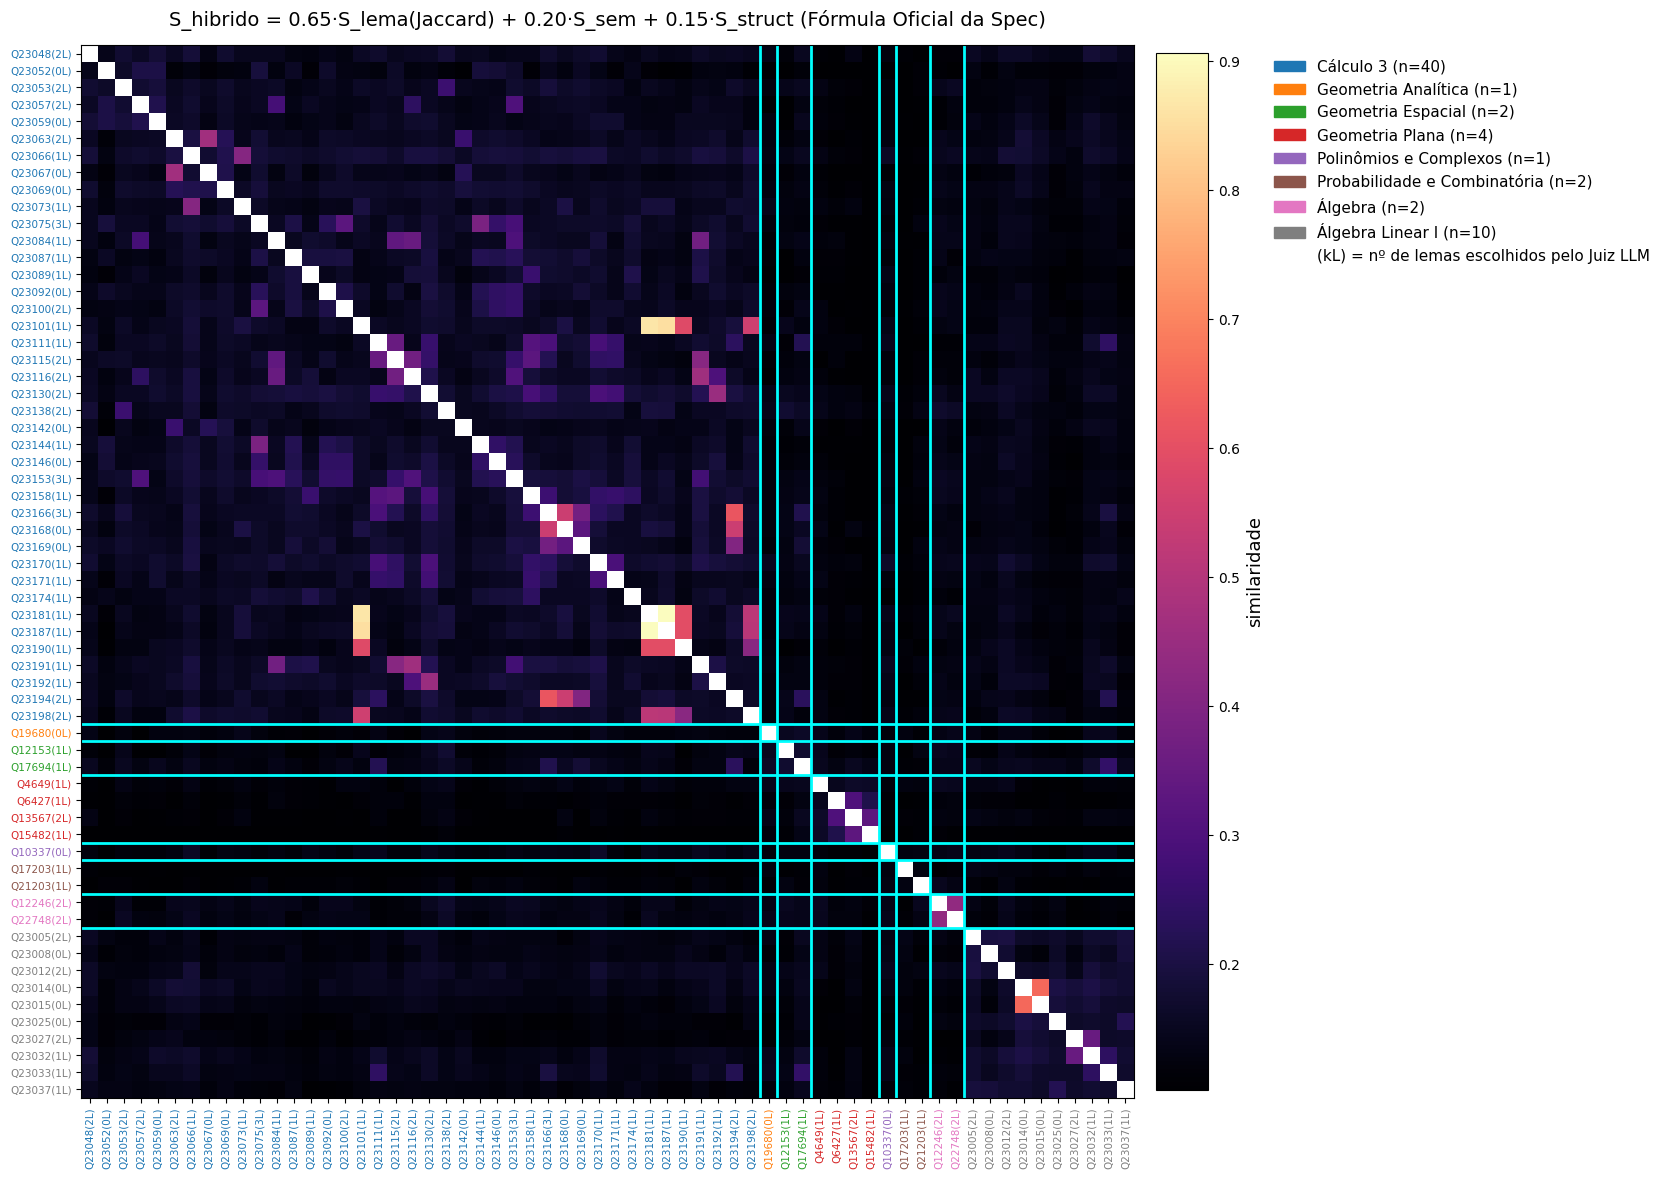

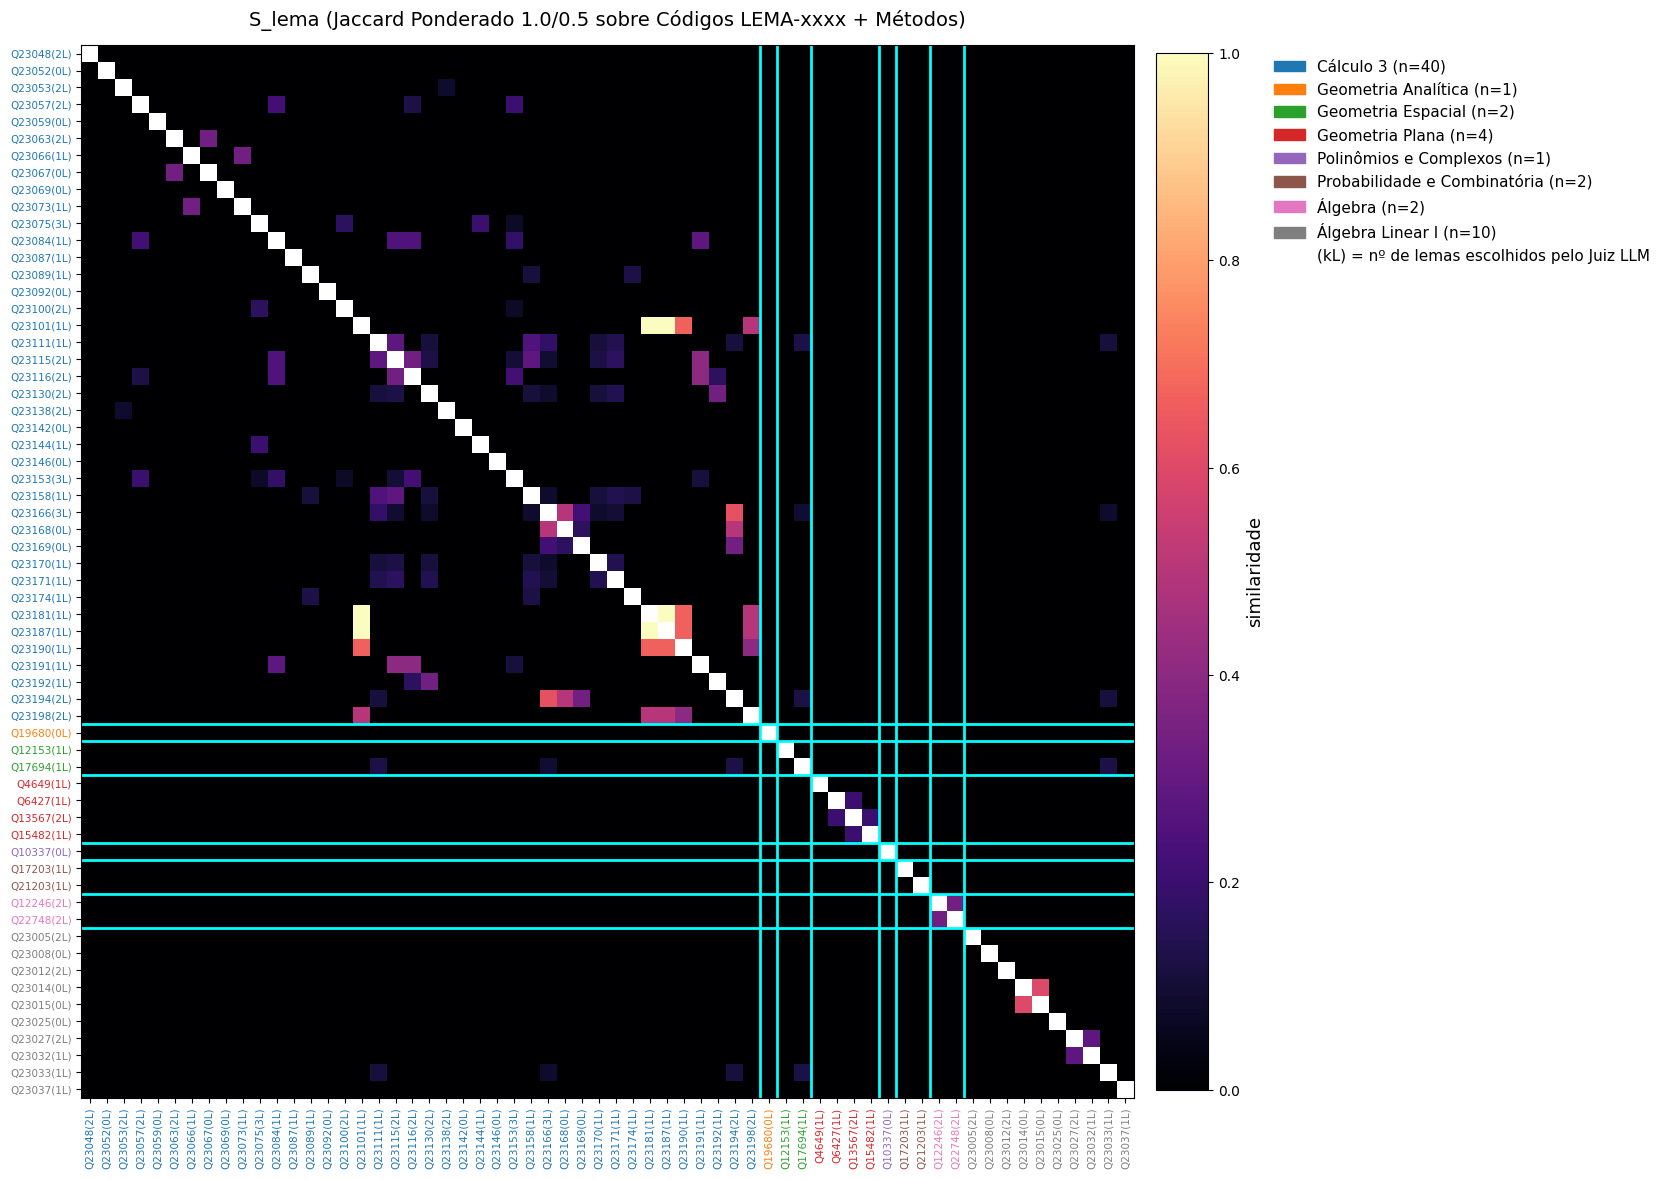

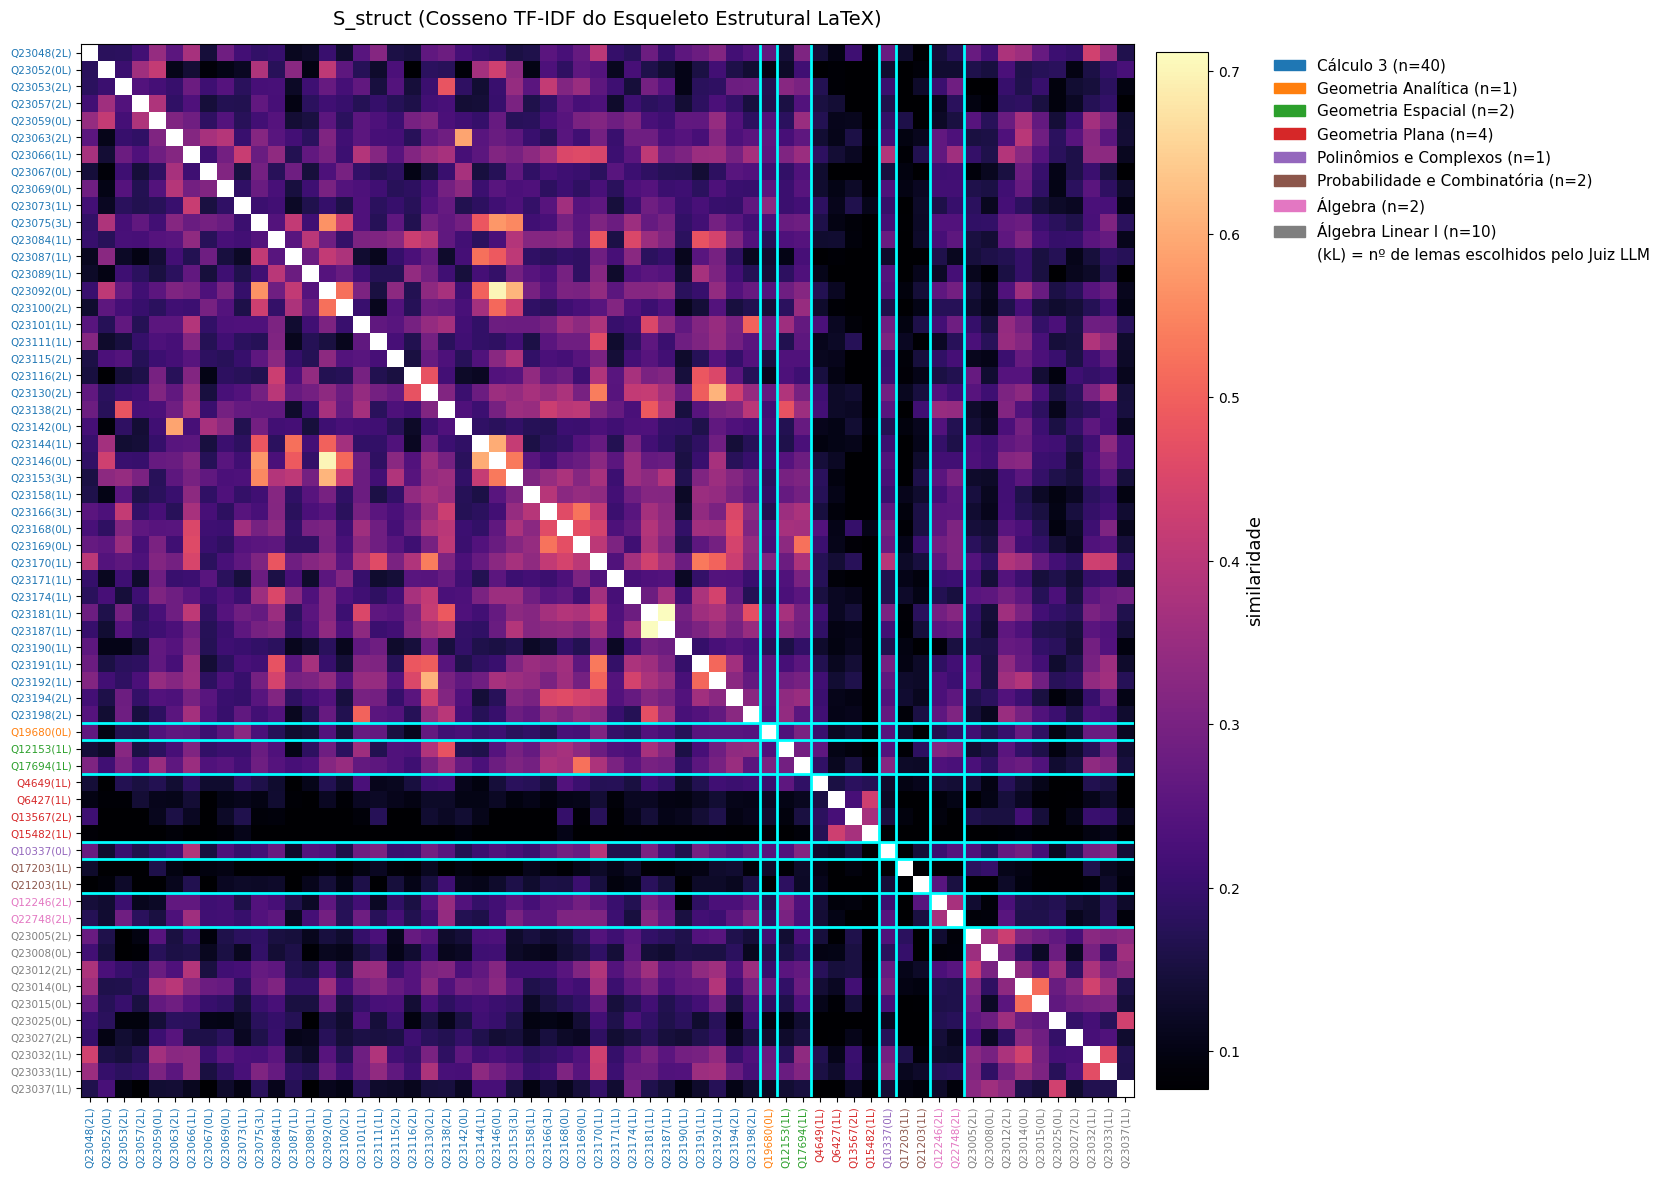


--- TOP 12 PARES MAIS SIMILARES PELO HÍBRIDO 3D DA SPEC ---
  Q23181 × Q23187 [Cálculo 3 / Cálculo 3] -> S_hibrido=0.906 (S_lema=1.000, S_sem=0.747, S_struct=0.711) | comuns=['LEMA-1767']
  Q23181 × Q23101 [Cálculo 3 / Cálculo 3] -> S_hibrido=0.865 (S_lema=1.000, S_sem=0.738, S_struct=0.452) | comuns=['LEMA-1767']
  Q23187 × Q23101 [Cálculo 3 / Cálculo 3] -> S_hibrido=0.855 (S_lema=1.000, S_sem=0.777, S_struct=0.333) | comuns=['LEMA-1767']
  Q23014 × Q23015 [Álgebra Linear I / Álgebra Linear I] -> S_hibrido=0.654 (S_lema=0.600, S_sem=0.931, S_struct=0.517) | comuns=['slug:verificacao-de-fechamento-sob-adicao', 'slug:verificacao-de-fechamento-sob-multiplicacao-por-escalar']
  Q23166 × Q23194 [Cálculo 3 / Cálculo 3] -> S_hibrido=0.616 (S_lema=0.625, S_sem=0.711, S_struct=0.452) | comuns=['LEMA-1796', 'LEMA-2734', 'slug:gradiente']
  Q23181 × Q23190 [Cálculo 3 / Cálculo 3] -> S_hibrido=0.598 (S_lema=0.667, S_sem=0.605, S_struct=0.293) | comuns=['LEMA-1767']
  Q23187 × Q23190 [Cálculo 3 /

In [8]:
# 10.1. Heatmaps Grandes da Similaridade Híbrida 3D (S_hibrido, S_lema_jaccard, S_sem, S_struct)
import json, shutil
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

drive_dir = Path("/content/drive/MyDrive/lemmas-pipeline")
if not drive_dir.parent.exists():
    from google.colab import drive
    drive.mount("/content/drive")

def carregar(nome):
    local = Path(nome)
    if not local.exists():
        origem = drive_dir / nome
        if not origem.exists():
            raise FileNotFoundError(f"Arquivo '{nome}' ainda não existe. Você precisa rodar a Célula 10 (Juiz LLM) ANTES desta célula 10.1!")
        shutil.copy(origem, local)
        print(f"[Drive -> /content] {nome}")
    return local

anc_llm = json.load(open(carregar("ancoragem_llm_62.json"), encoding="utf-8"))
rel_hib = json.load(open(carregar("similaridade_hibrida_62_relatorio.json"), encoding="utf-8"))
M_hib = np.load(carregar("similaridade_hibrida_62.npz"))

info = {r["id"]: r for r in anc_llm}
ids = [int(i) for i in M_hib["ids"]]
mat_of = lambda qid: info[qid].get("materia") or "?"
order = sorted(range(len(ids)), key=lambda i: (mat_of(ids[i]), ids[i]))
ids_ord = [ids[i] for i in order]
materias = sorted({mat_of(q) for q in ids})
cores = dict(zip(materias, plt.cm.tab10.colors))
tamanhos = [sum(1 for q in ids_ord if mat_of(q) == m) for m in materias]
bounds = np.cumsum(tamanhos)[:-1]

MATRIZES_PLOT = [
    ("S_hibrido", "S_hibrido = 0.65·S_lema(Jaccard) + 0.20·S_sem + 0.15·S_struct (Fórmula Oficial da Spec)"),
    ("S_lema_jaccard", "S_lema (Jaccard Ponderado 1.0/0.5 sobre Códigos LEMA-xxxx + Métodos)"),
    ("S_struct", "S_struct (Cosseno TF-IDF do Esqueleto Estrutural LaTeX)"),
]

for key, titulo in MATRIZES_PLOT:
    S = M_hib[key][np.ix_(order, order)].copy()
    np.fill_diagonal(S, np.nan)
    fig, ax = plt.subplots(figsize=(16, 14))
    vmin = 0.0 if key == "S_lema_jaccard" else float(np.nanpercentile(S, 5))
    im = ax.imshow(S, cmap="magma", vmin=vmin, vmax=float(np.nanmax(S) or 1.0), interpolation="nearest")
    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
    cb.set_label("similaridade", fontsize=13)

    labels = [f"Q{q}({info[q]['n_lemas_escolhidos']}L)" for q in ids_ord]
    ax.set_xticks(range(len(ids_ord)))
    ax.set_yticks(range(len(ids_ord)))
    ax.set_xticklabels(labels, rotation=90, fontsize=7.5)
    ax.set_yticklabels(labels, fontsize=7.5)
    for tick, q in zip(ax.get_xticklabels(), ids_ord):
        tick.set_color(cores[mat_of(q)])
    for tick, q in zip(ax.get_yticklabels(), ids_ord):
        tick.set_color(cores[mat_of(q)])

    for b in bounds:
        ax.axhline(b - 0.5, color="cyan", lw=2)
        ax.axvline(b - 0.5, color="cyan", lw=2)

    ax.set_title(titulo, fontsize=14, pad=14)
    ax.legend(
        handles=[Patch(color=cores[m], label=f"{m} (n={n})") for m, n in zip(materias, tamanhos)]
        + [Patch(color="white", label="(kL) = nº de lemas escolhidos pelo Juiz LLM")],
        loc="upper left", bbox_to_anchor=(1.12, 1.0), fontsize=11, frameon=False,
    )
    plt.tight_layout()
    out_png = f"hibrido_62_heatmap_{key}.png"
    fig.savefig(out_png, dpi=160, bbox_inches="tight")
    if drive_dir.parent.exists():
        shutil.copy(out_png, drive_dir / out_png)
    plt.show()

print("\n--- TOP 12 PARES MAIS SIMILARES PELO HÍBRIDO 3D DA SPEC ---")
for p in rel_hib["top_pares_hibrido_3d"][:12]:
    print(
        f"  Q{p['q_a']} × Q{p['q_b']} [{p['materia_a']} / {p['materia_b']}] -> "
        f"S_hibrido={p['S_hibrido']:.3f} (S_lema={p['S_lema_jaccard']:.3f}, S_sem={p['S_sem']:.3f}, S_struct={p['S_struct']:.3f}) | "
        f"comuns={p['chaves_em_comum']}"
    )
